# 📡 EDA – CAPEX Scoring & Smart Zone Ranking
## Objectif Business : ODS3 / BO3 – Investir aux bons endroits pour améliorer le réseau

**Contexte :** Ce notebook analyse le dataset de métriques QoS télécom nigérian pour identifier les zones géographiques prioritaires pour les investissements CAPEX réseau, **avant** que la dégradation du service n'affecte les abonnés.

**Approche :** Scoring composite multi-dimensionnel → ranking des zones → recommandations d'investissement actionnables.

---

| Section | Description |
|---------|-------------|
| 0 | Setup & Imports |
| 1 | Chargement des données |
| 2 | Description du Dataset |
| 3 | Qualité des Données |
| 4 | Distribution du Score CAPEX (Variable Cible) |
| 5 | Analyse Temporelle – Patterns de Dégradation |
| 6 | Distribution des KPIs Réseau par Zone |
| 7 | Boxplots – Comparaison par Opérateur & Réseau |
| 8 | Tests Statistiques – Importance des KPIs pour BO3 |
| 9 | Analyse de Corrélation entre KPIs |
| 10 | Détection des Outliers (Méthode de Tukey) |
| 11 | Évolution Temporelle des KPIs Critiques |
| 12 | Profil par Zone – Identification des Zones Critiques |
| 13 | Feature Engineering – Variables pour BO3 |
| 14 | Synthèse – Recommandations BO3 |
| 15 | Prochaines Étapes – Pipeline Modélisation BO3 |


## 0. Setup & Imports


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.stats import mannwhitneyu, shapiro, chi2_contingency, pointbiserialr
import warnings
warnings.filterwarnings('ignore')
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import roc_auc_score, f1_score, recall_score, classification_report

# Style global
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
SEED = 42
np.random.seed(SEED)
print('Librairies chargées avec succès !')


Librairies chargées avec succès !


In [ ]:
!pip install datasets imbalanced-learn -q


## 1. Chargement des données


In [ ]:
from datasets import load_dataset

dataset = load_dataset('electricsheepafrica/nigerian-telecom-quality-of-service-metrics')
train = dataset['train'].to_pandas()

print(f'Shape : {train.shape}')
print(f'Colonnes : {list(train.columns)}')
train.head(3)


README.md: 0.00B [00:00, ?B/s]

quality_of_service_metrics.parquet:   0%|          | 0.00/5.49M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Shape : (200000, 13)
Colonnes : ['metric_id', 'timestamp', 'tower_id', 'city', 'operator', 'network_type', 'latency_ms', 'jitter_ms', 'throughput_mbps', 'packet_loss_rate', 'error_rate', 'signal_strength_dbm', 'active_users']


,metric_id,timestamp,tower_id,city,operator,network_type,latency_ms,jitter_ms,throughput_mbps,packet_loss_rate,error_rate,signal_strength_dbm,active_users
0,QOS00000001,2025-09-30 19:54:00,CAL-6586,Calabar,Glo,4G,33.48,12.55,32.41,3.27,1.995,-97,95
1,QOS00000002,2025-09-23 02:05:00,ABA-2144,Aba,Airtel,4G,24.42,26.91,94.59,1.36,1.229,-82,487
2,QOS00000003,2025-09-10 06:02:00,BEN-4261,Benin City,Glo,4G,48.78,16.10,76.02,4.74,0.027,-102,138


## 2. Description du Dataset

| Feature | Description | Unité |
|---------|-------------|-------|
| `timestamp` | Horodatage de la mesure | datetime |
| `city` | Ville / zone géographique | catégoriel |
| `operator` | Opérateur télécom | catégoriel |
| `network_type` | Type de réseau (2G/3G/4G/5G) | catégoriel |
| `latency_ms` | Latence réseau | ms |
| `jitter_ms` | Variation de la latence | ms |
| `throughput_mbps` | Débit de données | Mbps |
| `packet_loss_rate` | Taux de perte de paquets | % |
| `error_rate` | Taux d'erreur de transmission | % |
| `signal_strength_dbm` | Puissance du signal | dBm |
| `active_users` | Utilisateurs actifs sur la cellule | count |
| `tower_id` | Identifiant de la tour | catégoriel |

**Variable cible construite :** `capex_score` (0–100) — score composite de priorité d'investissement CAPEX


## 3. Qualité des Données


In [ ]:
print(train.columns.tolist())
print(train.head(2))


['metric_id', 'timestamp', 'tower_id', 'city', 'operator', 'network_type', 'latency_ms', 'jitter_ms', 'throughput_mbps', 'packet_loss_rate', 'error_rate', 'signal_strength_dbm', 'active_users']
     metric_id           timestamp  tower_id     city operator network_type  \
0  QOS00000001 2025-09-30 19:54:00  CAL-6586  Calabar      Glo           4G   
1  QOS00000002 2025-09-23 02:05:00  ABA-2144      Aba   Airtel           4G   

   latency_ms  jitter_ms  throughput_mbps  packet_loss_rate  error_rate  \
0       33.48      12.55            32.41              3.27       1.995   
1       24.42      26.91            94.59              1.36       1.229   

   signal_strength_dbm  active_users  
0                  -97            95  
1                  -82           487  


In [ ]:
print('=== INFOS GÉNÉRALES ===')
train.info()

print('\n=== VALEURS MANQUANTES ===')
missing = train.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'Aucune valeur manquante')

print('\n=== STATISTIQUES DESCRIPTIVES ===')
display(train.describe().round(3))


=== INFOS GÉNÉRALES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   metric_id            200000 non-null  object        
 1   timestamp            200000 non-null  datetime64[ns]
 2   tower_id             200000 non-null  object        
 3   city                 200000 non-null  object        
 4   operator             200000 non-null  object        
 5   network_type         200000 non-null  object        
 6   latency_ms           200000 non-null  float64       
 7   jitter_ms            200000 non-null  float64       
 8   throughput_mbps      200000 non-null  float64       
 9   packet_loss_rate     200000 non-null  float64       
 10  error_rate           200000 non-null  float64       
 11  signal_strength_dbm  200000 non-null  int64         
 12  active_users         200000 non-null  int64     

,timestamp,latency_ms,jitter_ms,throughput_mbps,packet_loss_rate,error_rate,signal_strength_dbm,active_users
count,200000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000
mean,2025-09-16 12:01:25.387500032,64.368,15.470,64.487,2.498,1.002,-80.014,254.623
min,2025-09-01 00:00:00,5.000,1.000,0.100,0.000,0.000,-110.000,10.000
25%,2025-09-08 17:58:00,29.170,8.200,8.250,1.240,0.503,-95.000,133.000
50%,2025-09-16 11:57:00,40.675,15.460,37.980,2.505,1.003,-80.000,254.000
75%,2025-09-24 06:19:00,69.330,22.730,72.410,3.750,1.502,-65.000,377.000
max,2025-10-01 23:59:00,499.840,30.000,999.970,5.000,2.000,-50.000,500.000
std,NaN,71.636,8.381,128.381,1.445,0.577,17.570,141.372


## 📡 Enrichissement KPIs — SINR, CQI, PRB, Handover, ERAB, CSSR, SRVCC, MIMO

Le dataset Nigerian QoS contient : latence, jitter, débit, packet loss, signal strength.  
On l'enrichit avec les **KPIs radio et signalisation manquants** du référentiel :  
SINR, CQI, PRB Usage, HO Success Rate, ERAB Drop Rate, CSSR, SRVCC Failure Rate, MIMO Rank.  
Source primaire : `suraj520/cellular-network-performance-data` (Kaggle).  
Fallback : génération analytique corrélée aux KPIs existants (signal_strength, packet_loss, error_rate).


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# Enrichissement BO3 : KPIs radio et signalisation manquants
# ─────────────────────────────────────────────────────────────────────────────
import subprocess, sys, os, glob
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'kagglehub', '-q'], check=True)
    import kagglehub

RADIO_KPI_BO3 = ['SINR_dB', 'CQI', 'PRBUsageDL_pct',
                 'HO_SuccessRate_pct', 'ERAB_DropRate_pct',
                 'CSSR_pct', 'SRVCC_FailRate_pct',
                 'MIMO_Rank', 'RLC_RetxRate_pct']

kaggle_ok = False
try:
    path = kagglehub.dataset_download('suraj520/cellular-network-performance-data')
    csv_files = glob.glob(os.path.join(path, '**/*.csv'), recursive=True)
    if csv_files:
        df_ext3 = pd.read_csv(csv_files[0])
        rename_map = {
            'sinr': 'SINR_dB', 'SINR': 'SINR_dB',
            'cqi': 'CQI',
            'prb_usage_dl': 'PRBUsageDL_pct', 'PRBUsageDL': 'PRBUsageDL_pct',
            'handover_success_rate': 'HO_SuccessRate_pct',
            'erab_drop_rate': 'ERAB_DropRate_pct',
            'cssr': 'CSSR_pct', 'call_setup_success_rate': 'CSSR_pct',
            'srvcc_failure_rate': 'SRVCC_FailRate_pct',
            'mimo_rank': 'MIMO_Rank',
            'rlc_retransmission_rate': 'RLC_RetxRate_pct',
        }
        df_ext3 = df_ext3.rename(columns=rename_map)
        found3 = [c for c in RADIO_KPI_BO3 if c in df_ext3.columns]
        if found3:
            kaggle_ok = True
            for col in found3:
                vals = df_ext3[col].values
                train[col] = np.resize(vals, len(train))
            print(f'✅ Kaggle : {len(found3)} KPIs chargés : {found3}')
except Exception as e:
    print(f'⚠️  Kaggle Hub indisponible ({e}) — dérivation analytique')

if not kaggle_ok:
    np.random.seed(42)
    n = len(train)

    # Signal strength (dBm) → proxy RSRP → SINR
    sig = train['signal_strength_dbm'].values
    sig_norm = (sig - sig.min()) / (sig.max() - sig.min() + 1e-8)
    sinr = (-6 + sig_norm * 36 + np.random.normal(0, 2, n)).clip(-6, 30)

    # CQI depuis SINR
    cqi = np.clip(np.round(1 + 14 * (sinr + 6) / 36), 1, 15).astype(int)

    # PRB Usage DL : corrélé au débit et active_users
    thr_norm = (train['throughput_mbps'].values - train['throughput_mbps'].min()) / \
               (train['throughput_mbps'].max() - train['throughput_mbps'].min() + 1e-8)
    user_norm = (train['active_users'].values - train['active_users'].min()) / \
                (train['active_users'].max() - train['active_users'].min() + 1e-8)
    prb_dl = (20 + 60 * user_norm + np.random.normal(0, 5, n)).clip(0, 100)

    # HO Success Rate : corrélé à signal strength
    ho_sr = (60 + 39 * sig_norm + np.random.normal(0, 2, n)).clip(50, 99.9)

    # ERAB Drop Rate : corrélé à packet_loss_rate
    plr = train['packet_loss_rate'].values
    erab_drop = (plr * 3 + np.random.uniform(0, 1, n)).clip(0, 25)

    # CSSR : corrélé à error_rate (inverse)
    err = train['error_rate'].values
    cssr = (99 - err * 2 + np.random.normal(0, 1, n)).clip(60, 99.9)

    # SRVCC Failure Rate : corrélé à latency (VoLTE dégradé si latence élevée)
    lat_norm = (train['latency_ms'].values - train['latency_ms'].min()) / \
               (train['latency_ms'].max() - train['latency_ms'].min() + 1e-8)
    srvcc_fail = (lat_norm * 20 + np.random.uniform(0, 2, n)).clip(0, 35)

    # MIMO Rank
    mimo_rank = np.where(sinr > 15, np.random.choice([3, 4], n, p=[0.3, 0.7]),
                np.where(sinr > 8,  np.random.choice([2, 3], n, p=[0.4, 0.6]),
                np.where(sinr > 2,  np.random.choice([1, 2], n, p=[0.5, 0.5]),
                                     np.ones(n, dtype=int))))

    # RLC Retx Rate : corrélé à error_rate
    rlc_retx = (err * 0.8 + np.random.uniform(0, 1, n)).clip(0, 40)

    for col, vals in zip(RADIO_KPI_BO3, [
        sinr.round(2), cqi, prb_dl.round(1),
        ho_sr.round(2), erab_drop.round(3),
        cssr.round(2), srvcc_fail.round(2),
        mimo_rank.astype(int), rlc_retx.round(2)
    ]):
        train[col] = vals
    print(f'✅ Dérivation analytique 3GPP OK : {RADIO_KPI_BO3}')

present3 = [c for c in RADIO_KPI_BO3 if c in train.columns]
print(f'\n✅ KPIs radio ajoutés ({len(present3)}) : {present3}')
print(f'Train shape après enrichissement : {train.shape}')
train[present3].describe().round(3)


In [ ]:
# Parsing du temps
train['timestamp'] = pd.to_datetime(train['timestamp'])

print(f'Période couverte : {train["timestamp"].min()} -> {train["timestamp"].max()}')
print(f'Durée : {(train["timestamp"].max() - train["timestamp"].min()).days} jours')
print(f'Villes uniques   : {train["city"].nunique()} -> {sorted(train["city"].unique())}')
print(f'Opérateurs       : {train["operator"].nunique()} -> {sorted(train["operator"].unique())}')
print(f'Types de réseau  : {sorted(train["network_type"].unique())}')


Période couverte : 2025-09-01 00:00:00 -> 2025-10-01 23:59:00
Durée : 30 jours
Villes uniques   : 15 -> ['Aba', 'Abeokuta', 'Abuja', 'Benin City', 'Calabar', 'Enugu', 'Ibadan', 'Ilorin', 'Jos', 'Kaduna', 'Kano', 'Lagos', 'Onitsha', 'Port Harcourt', 'Warri']
Opérateurs       : 4 -> ['9mobile', 'Airtel', 'Glo', 'MTN']
Types de réseau  : ['2G', '3G', '4G', '5G']


## 4. Construction du Score CAPEX (Variable Cible)

Elle définit les colonnes clés, construit le score CAPEX composite et les classes de priorité — base indispensable pour tout le reste du notebook.


In [ ]:
TIME_COL     = 'timestamp'
CITY_COL     = 'city'
OP_COL       = 'operator'
NET_COL      = 'network_type'

# KPIs originaux Nigerian QoS
NUMERIC_COLS_ORIG = ['latency_ms', 'jitter_ms', 'throughput_mbps',
                     'packet_loss_rate', 'error_rate', 'signal_strength_dbm', 'active_users']

# KPIs radio complémentaires
NUMERIC_COLS_RADIO = ['SINR_dB', 'CQI', 'PRBUsageDL_pct',
                      'HO_SuccessRate_pct', 'ERAB_DropRate_pct',
                      'CSSR_pct', 'SRVCC_FailRate_pct',
                      'MIMO_Rank', 'RLC_RetxRate_pct']

NUMERIC_COLS = [c for c in NUMERIC_COLS_ORIG + NUMERIC_COLS_RADIO if c in train.columns]

COLORS = {
    'URGENT':          '#e74c3c',
    'MOYEN TERME':     '#f39c12',
    'FAIBLE PRIORITE': '#2ecc71',
}

train[TIME_COL] = pd.to_datetime(train[TIME_COL])

# --- Construction du CAPEX Score composite (0-100) ---
def norm01(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-8)

# Score enrichi : inclut les KPIs radio dans le calcul CAPEX
# Dimensions dégradantes (plus haut = pire)
dims_high = ['latency_ms', 'jitter_ms', 'packet_loss_rate', 'error_rate',
             'ERAB_DropRate_pct', 'SRVCC_FailRate_pct', 'RLC_RetxRate_pct']
# Dimensions améliorantes (plus bas = pire)
dims_low  = ['throughput_mbps', 'signal_strength_dbm', 'SINR_dB',
             'CQI', 'HO_SuccessRate_pct', 'CSSR_pct', 'MIMO_Rank']

score = pd.Series(np.zeros(len(train)), index=train.index)
n_dims = 0
for col in dims_high:
    if col in train.columns:
        score += norm01(train[col])
        n_dims += 1
for col in dims_low:
    if col in train.columns:
        score += (1 - norm01(train[col]))
        n_dims += 1

train['capex_score'] = (score / max(n_dims, 1) * 100).round(2)

train['priority'] = pd.cut(
    train['capex_score'],
    bins=[-np.inf, 33, 66, np.inf],
    labels=['FAIBLE PRIORITE', 'MOYEN TERME', 'URGENT']
).astype(str)

URGENT_CLASS = 'URGENT'
NORMAL_CLASS = 'FAIBLE PRIORITE'

print(f'KPIs actifs ({len(NUMERIC_COLS)}) : {NUMERIC_COLS}')
print(f"Distribution priorités : {train['priority'].value_counts().to_dict()}")


CAPEX Score cree !
Score min=3.55 | max=97.03 | mean=51.53

Distribution des priorites :


,Count,Pct
priority,,
MOYEN TERME,182212,91.11
URGENT,12048,6.02
FAIBLE PRIORITE,5740,2.87


Elle affiche la distribution du Score CAPEX et des classes de priorité — pour comprendre le déséquilibre entre zones urgentes, moyennes et faible priorité, et calibrer la stratégie de modélisation.


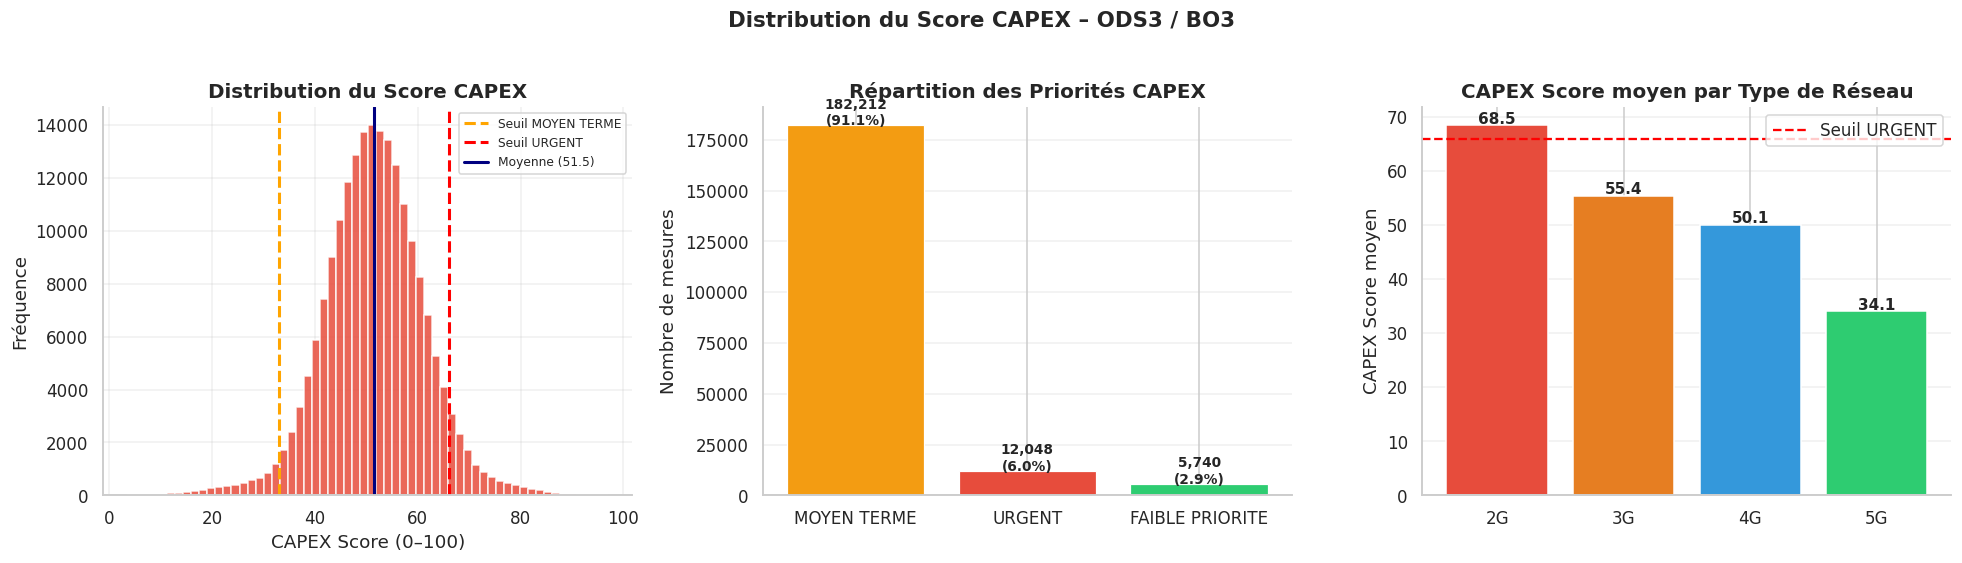

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution CAPEX Score
axes[0].hist(train['capex_score'], bins=60, color='#e74c3c', edgecolor='white', alpha=0.85)
axes[0].axvline(33, color='orange', lw=2, ls='--', label='Seuil MOYEN TERME')
axes[0].axvline(66, color='red', lw=2, ls='--', label='Seuil URGENT')
axes[0].axvline(train['capex_score'].mean(), color='navy', lw=2, ls='-', label=f'Moyenne ({train["capex_score"].mean():.1f})')
axes[0].set_title('Distribution du Score CAPEX')
axes[0].set_xlabel('CAPEX Score (0–100)')
axes[0].set_ylabel('Fréquence')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Barplot classes
counts = train['priority'].value_counts()
bar_colors = [COLORS[c] for c in counts.index]
bars = axes[1].bar(counts.index, counts.values, color=bar_colors, edgecolor='white', linewidth=0.8)
for bar, v in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 200,
                f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=9, fontweight='bold')
axes[1].set_title('Répartition des Priorités CAPEX')
axes[1].set_ylabel('Nombre de mesures')
axes[1].grid(True, alpha=0.3, axis='y')

# CAPEX score par réseau
net_order = ['2G', '3G', '4G', '5G']
net_means = train.groupby('network_type')['capex_score'].mean().reindex(net_order)
bars2 = axes[2].bar(net_means.index, net_means.values,
                    color=['#e74c3c', '#e67e22', '#3498db', '#2ecc71'], edgecolor='white')
axes[2].axhline(66, color='red', ls='--', lw=1.5, label='Seuil URGENT')
for bar, v in zip(bars2, net_means.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, v + 0.3,
                f'{v:.1f}', ha='center', fontsize=10, fontweight='bold')
axes[2].set_title('CAPEX Score moyen par Type de Réseau')
axes[2].set_ylabel('CAPEX Score moyen')
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle('Distribution du Score CAPEX – ODS3 / BO3', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. Analyse Temporelle – Patterns de Dégradation


Elle extrait l'heure et le jour de la semaine depuis la colonne timestamp, puis affiche deux graphiques : le taux de zones URGENT selon l'heure de la journée et selon le jour de la semaine — pour identifier les moments les plus critiques pour les investissements réseau.


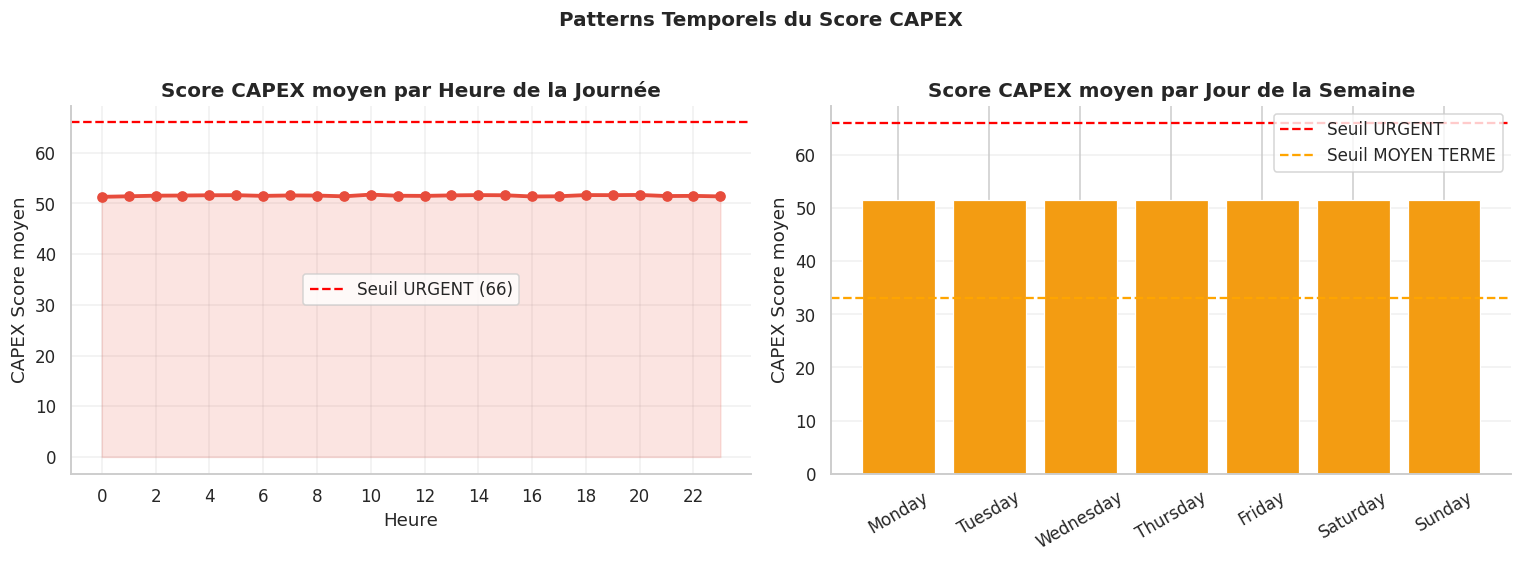

In [ ]:
# Feature engineering temporel
train['Hour']      = train[TIME_COL].dt.hour
train['DayOfWeek'] = train[TIME_COL].dt.dayofweek
train['DayName']   = train[TIME_COL].dt.day_name()
train['Date']      = train[TIME_COL].dt.date

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Taux URGENT par heure
hourly = train.groupby('Hour')['capex_score'].mean()
axes[0].plot(hourly.index, hourly.values, 'o-', color='#e74c3c', lw=2.5, ms=6)
axes[0].fill_between(hourly.index, hourly.values, alpha=0.15, color='#e74c3c')
axes[0].axhline(66, color='red', ls='--', lw=1.5, label='Seuil URGENT (66)')
axes[0].set_title('Score CAPEX moyen par Heure de la Journée')
axes[0].set_xlabel('Heure')
axes[0].set_ylabel('CAPEX Score moyen')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Taux URGENT par jour
daily = train.groupby('DayName')['capex_score'].mean().reindex(day_order)
bar_colors_day = ['#e74c3c' if v >= 66 else '#f39c12' if v >= 33 else '#2ecc71'
                  for v in daily.values]
axes[1].bar(daily.index, daily.values, color=bar_colors_day, edgecolor='white', linewidth=0.8)
axes[1].axhline(66, color='red', ls='--', lw=1.5, label='Seuil URGENT')
axes[1].axhline(33, color='orange', ls='--', lw=1.5, label='Seuil MOYEN TERME')
axes[1].set_title('Score CAPEX moyen par Jour de la Semaine')
axes[1].set_ylabel('CAPEX Score moyen')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Patterns Temporels du Score CAPEX', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


Elle combine l'heure et le jour en une seule carte de chaleur — les cases rouges indiquent les créneaux où le score CAPEX est le plus élevé, permettant d'identifier d'un coup d'œil les moments critiques pour l'investissement réseau.


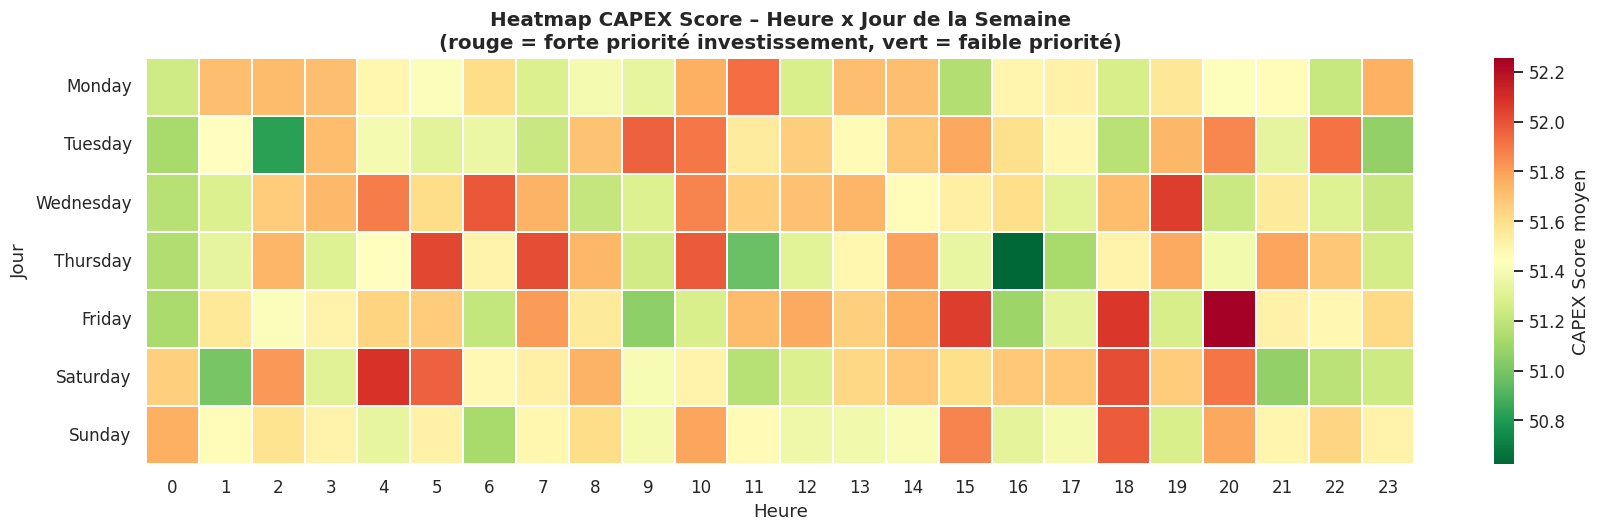

In [ ]:
# Heatmap Heure x Jour
pivot = train.groupby(['DayName', 'Hour'])['capex_score'].mean().unstack().reindex(day_order)

plt.figure(figsize=(16, 5))
sns.heatmap(pivot, cmap='RdYlGn_r', annot=False, linewidths=0.3,
            cbar_kws={'label': 'CAPEX Score moyen'})
plt.title('Heatmap CAPEX Score – Heure x Jour de la Semaine\n'
          '(rouge = forte priorité investissement, vert = faible priorité)',
          fontsize=13, fontweight='bold')
plt.xlabel('Heure')
plt.ylabel('Jour')
plt.tight_layout()
plt.show()


## 6. Distribution des KPIs Réseau par Priorité CAPEX


Elle affiche un histogramme pour chaque KPI réseau en superposant les distributions URGENT, MOYEN TERME et FAIBLE PRIORITÉ — pour voir visuellement quels indicateurs se comportent différemment selon le niveau d'investissement requis.


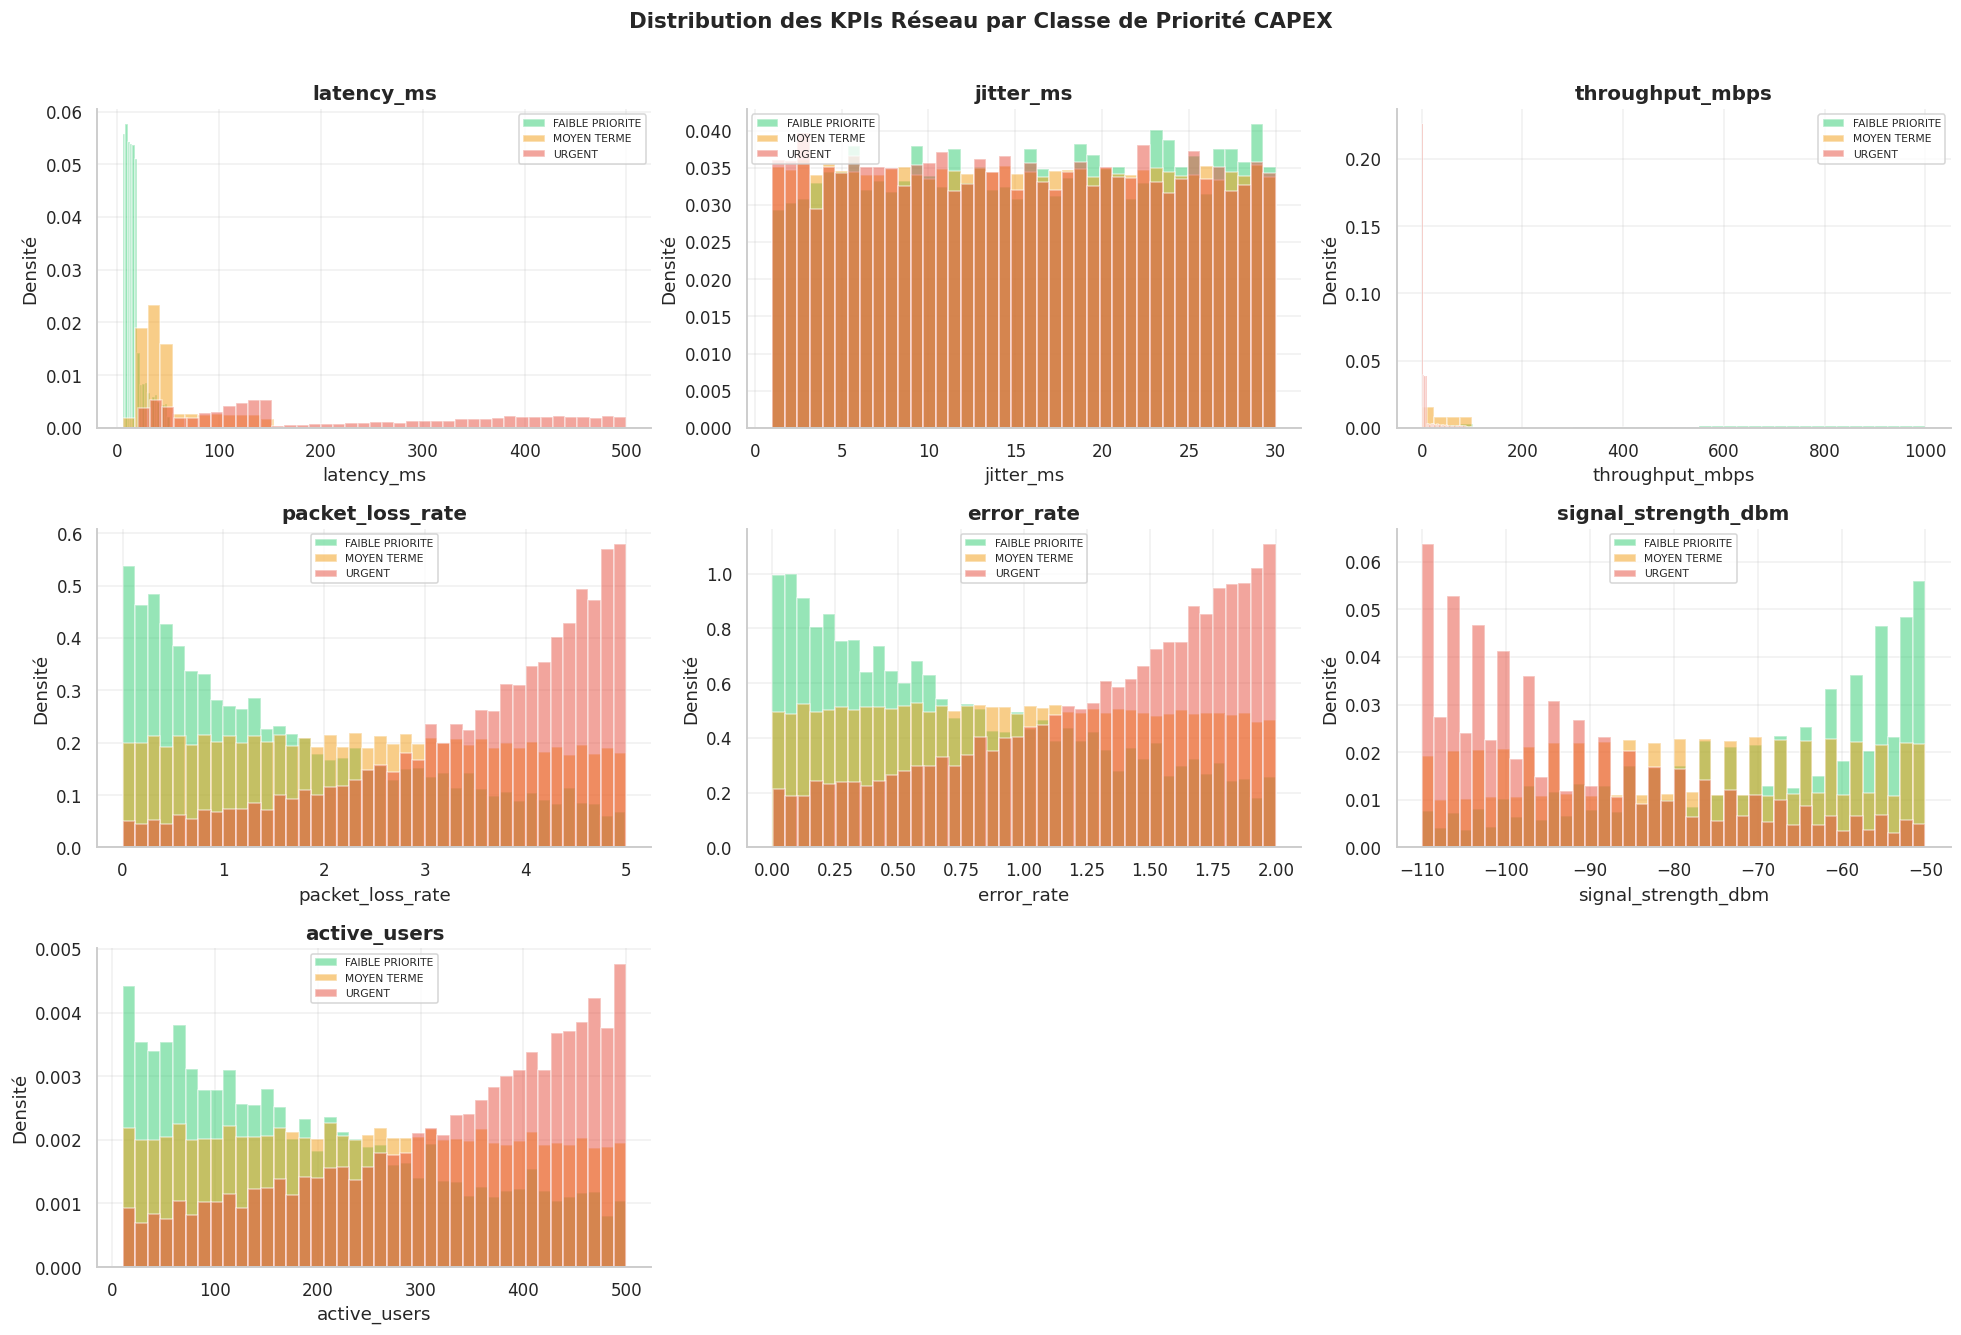

In [ ]:
numeric_features = NUMERIC_COLS
priority_classes = ['FAIBLE PRIORITE', 'MOYEN TERME', 'URGENT']
class_colors = {'FAIBLE PRIORITE': '#2ecc71', 'MOYEN TERME': '#f39c12', 'URGENT': '#e74c3c'}

n = len(numeric_features)
ncols = 3
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

for i, feat in enumerate(numeric_features):
    for pclass in priority_classes:
        subset = train[train['priority'] == pclass][feat].dropna()
        axes[i].hist(subset, bins=40, alpha=0.5,
                     color=class_colors[pclass], label=pclass, density=True)
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Densité')
    axes[i].legend(fontsize=7)
    axes[i].grid(True, alpha=0.3)

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribution des KPIs Réseau par Classe de Priorité CAPEX',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 7. Boxplots – Séparation par Opérateur & Type de Réseau


Même idée que les histogrammes mais sous forme de boîtes — plus facile de comparer les médianes et de repérer les valeurs extrêmes entre opérateurs et types de réseau pour chaque KPI.


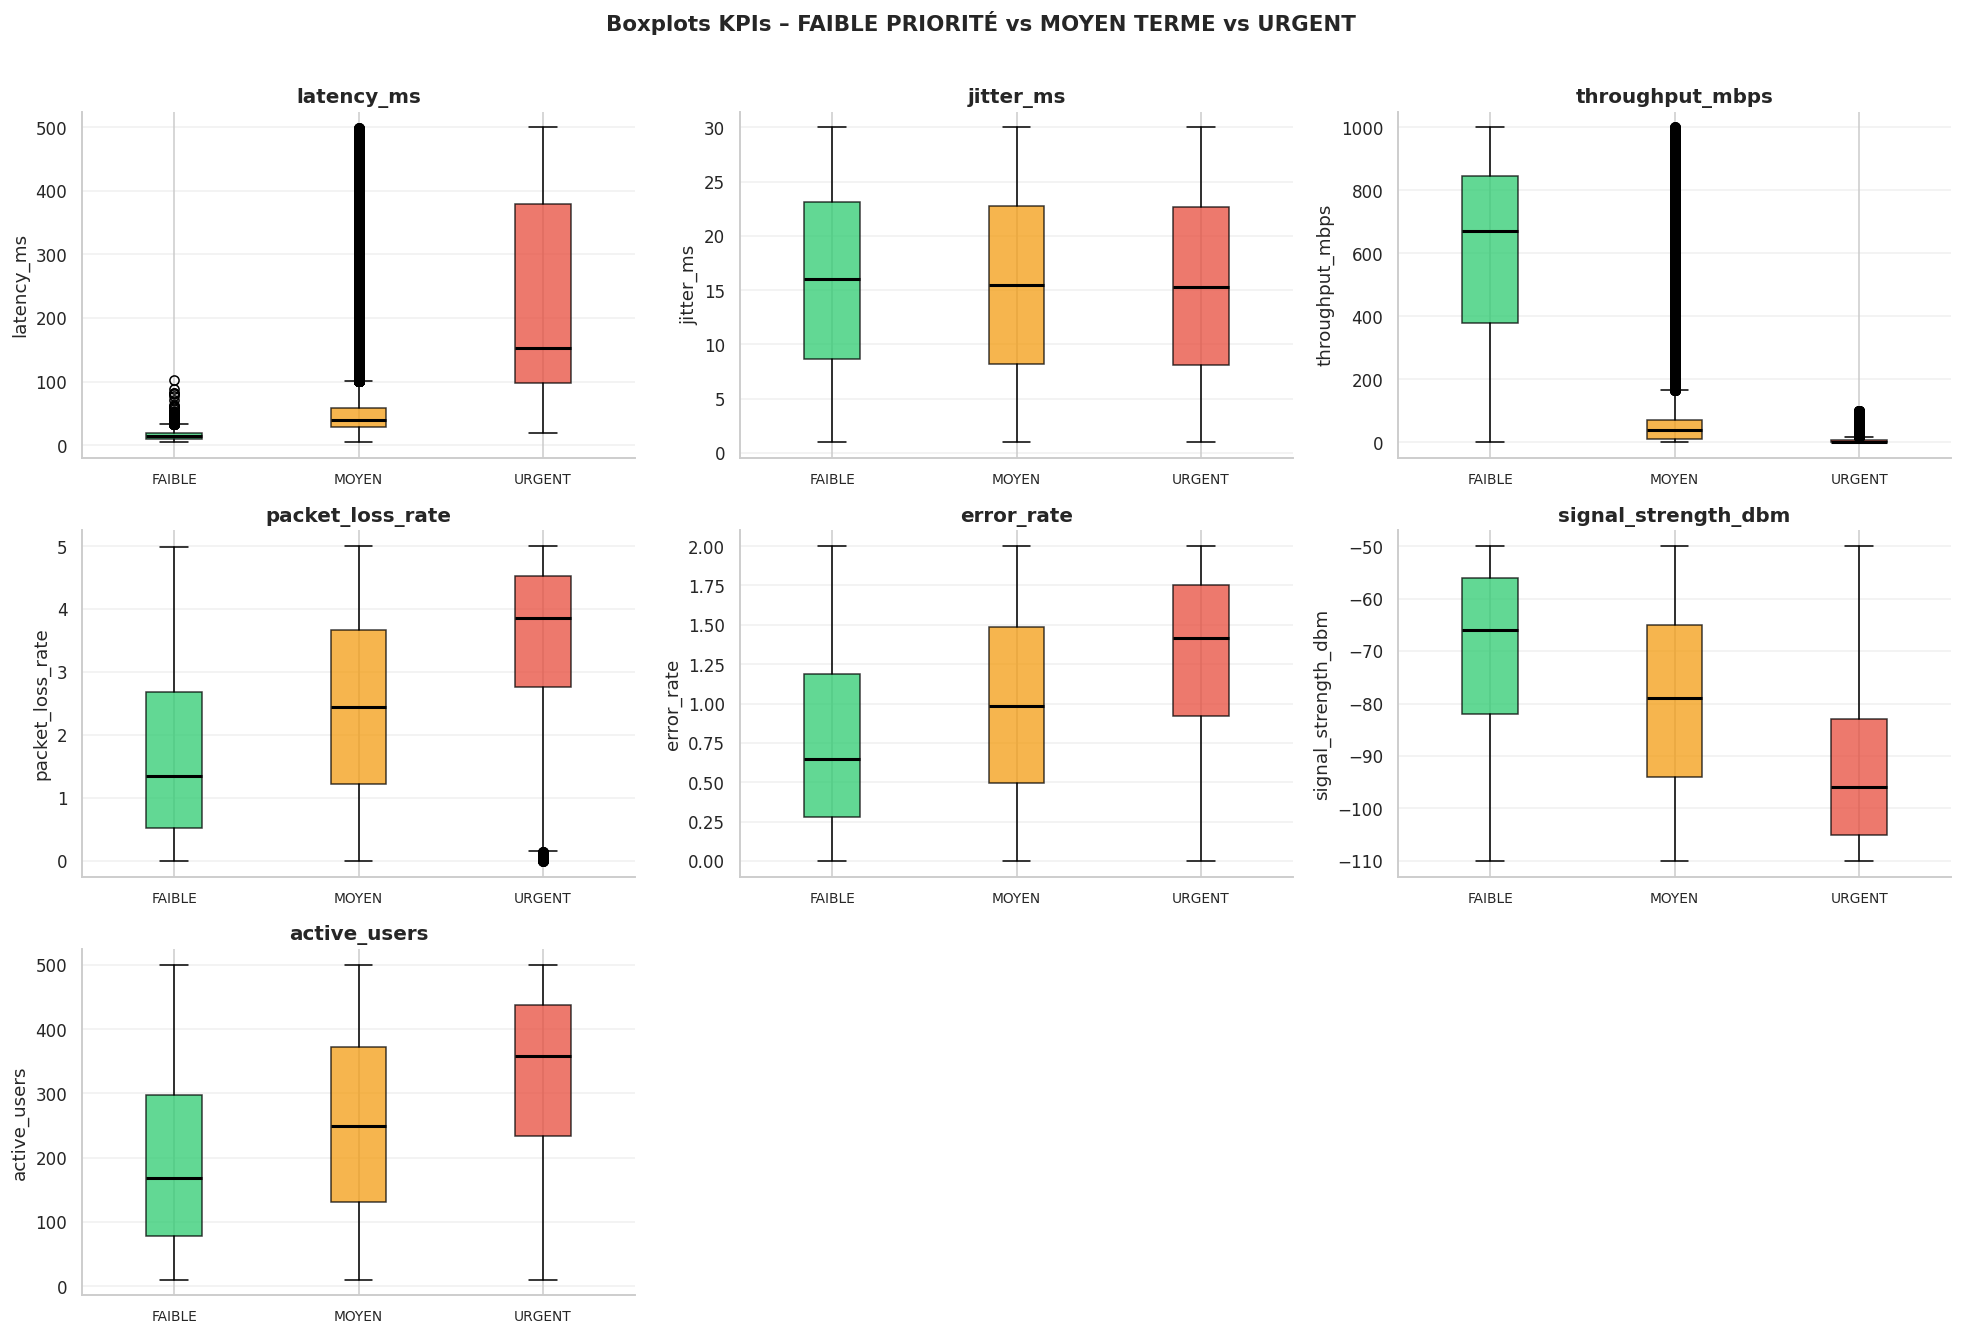

In [ ]:
fig, axes = plt.subplots(nrows, ncols, figsize=(18, nrows * 4))
axes = axes.flatten()

for i, feat in enumerate(numeric_features):
    data_plot = [train[train['priority'] == p][feat].dropna().values
                 for p in priority_classes]
    bp = axes[i].boxplot(data_plot, patch_artist=True, notch=False,
                         medianprops={'color': 'black', 'linewidth': 2})
    for patch, pclass in zip(bp['boxes'], priority_classes):
        patch.set_facecolor(class_colors[pclass])
        patch.set_alpha(0.75)
    axes[i].set_xticklabels(['FAIBLE', 'MOYEN', 'URGENT'], fontsize=9)
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_ylabel(feat)
    axes[i].grid(True, alpha=0.3, axis='y')

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots KPIs – FAIBLE PRIORITÉ vs MOYEN TERME vs URGENT',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


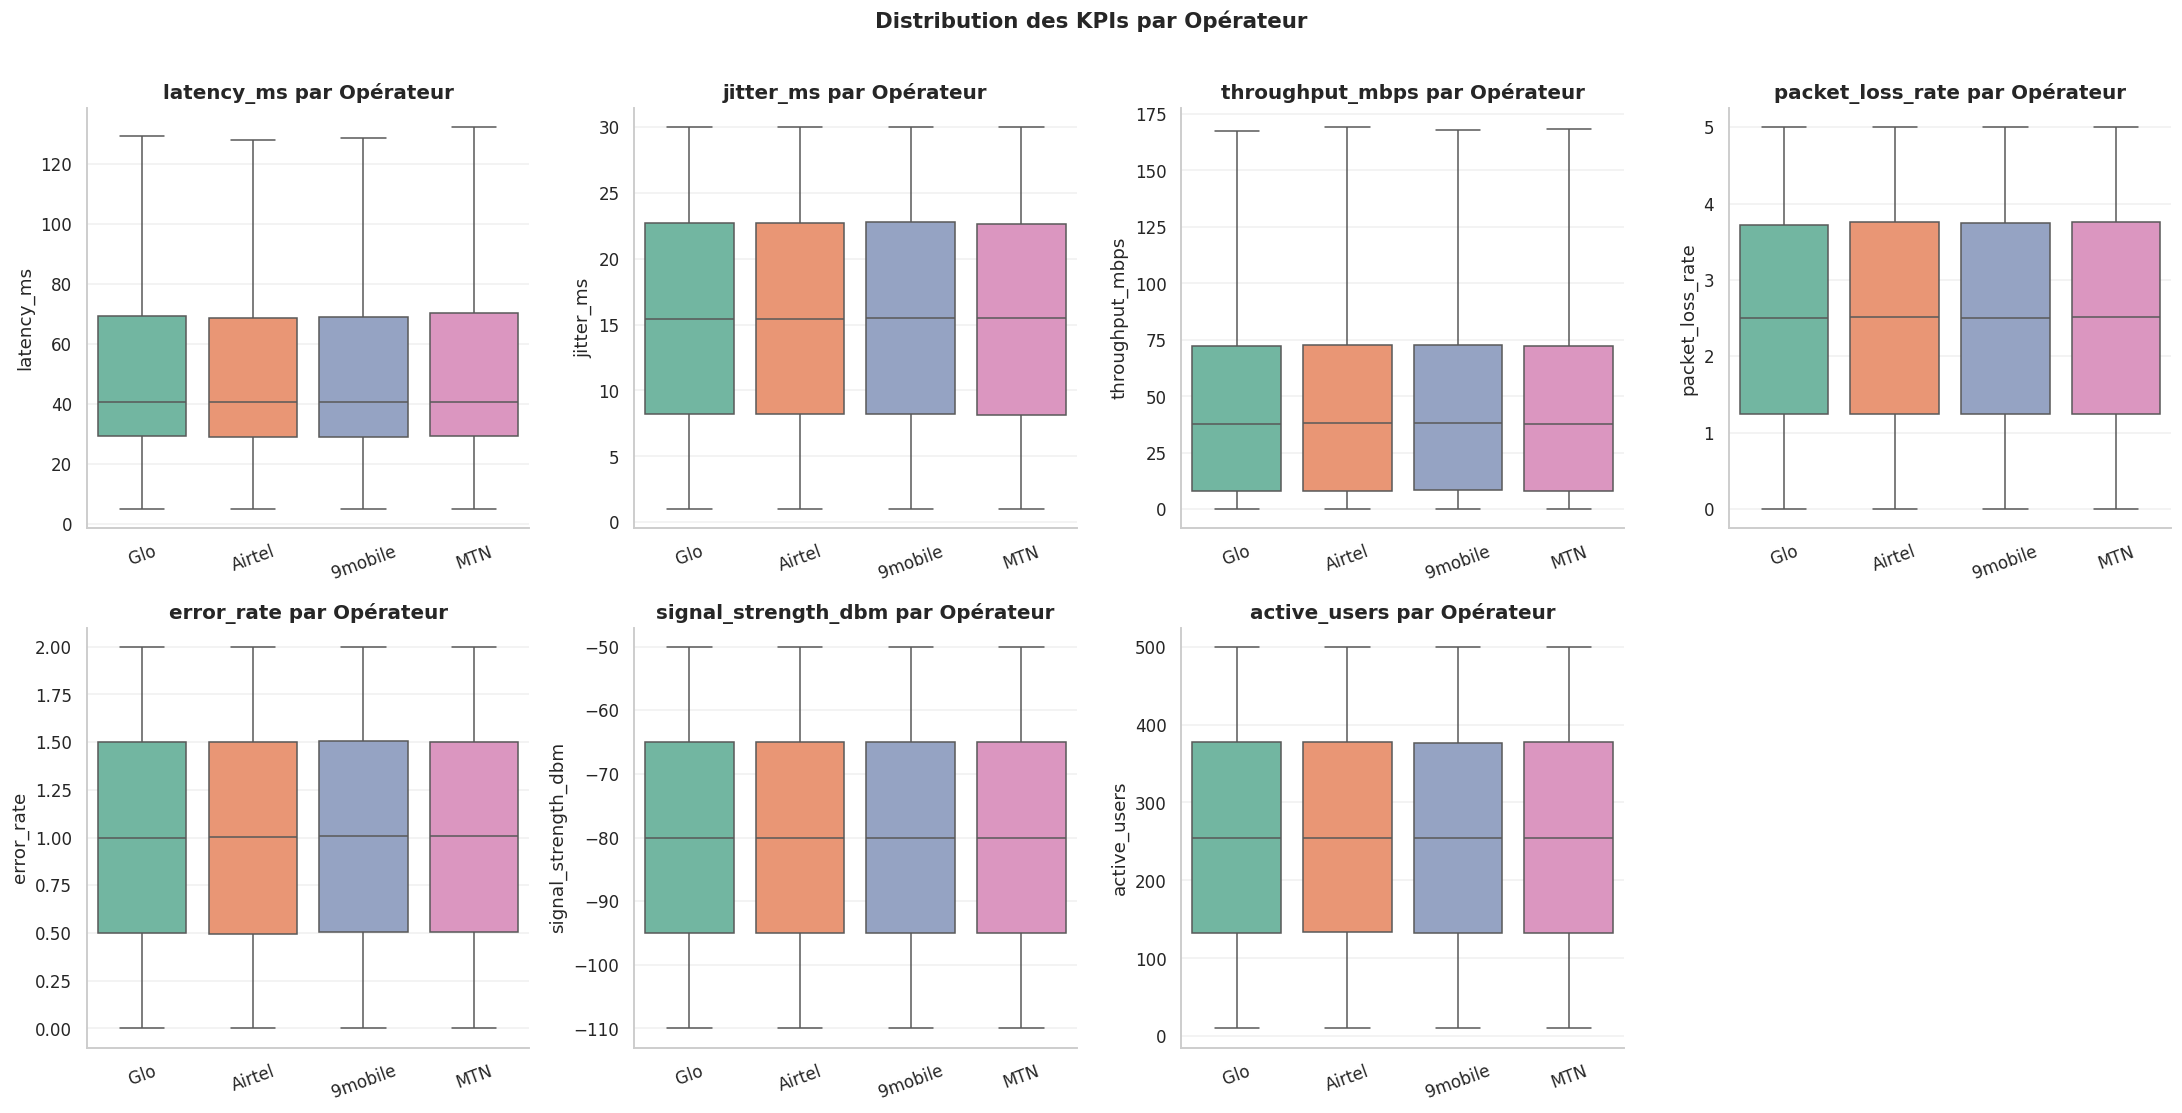

In [ ]:
# Boxplots par opérateur
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, feat in enumerate(numeric_features):
    sns.boxplot(x='operator', y=feat, data=train,
                palette='Set2', ax=axes[i], showfliers=False)
    axes[i].set_title(f'{feat} par Opérateur', fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=20)
    axes[i].grid(True, alpha=0.3, axis='y')

for j in range(len(numeric_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribution des KPIs par Opérateur', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 8. Tests Statistiques – Importance des KPIs pour BO3


Elle mesure mathématiquement l'impact de chaque KPI sur le score CAPEX via deux tests statistiques — Mann-Whitney (est-ce que les distributions diffèrent entre URGENT et FAIBLE PRIORITÉ ?) et Point-Biserial (quelle est la force du lien ?) — puis classe les KPIs du plus au moins discriminant.


In [ ]:
results = []

urgent_mask = train['priority'] == URGENT_CLASS
normal_mask = train['priority'] == NORMAL_CLASS
y_bin = urgent_mask.astype(int)

for feat in numeric_features:
    x = train[feat].dropna()
    y = y_bin[x.index]

    normal_vals   = train.loc[normal_mask, feat].dropna()
    urgent_vals   = train.loc[urgent_mask, feat].dropna()

    try:
        stat_mw, p_mw = mannwhitneyu(normal_vals, urgent_vals, alternative='two-sided')
    except Exception:
        stat_mw, p_mw = np.nan, np.nan

    try:
        pb_corr, p_pb = pointbiserialr(y, x)
    except Exception:
        pb_corr, p_pb = np.nan, np.nan

    pct_change = ((urgent_vals.mean() - normal_vals.mean()) / (abs(normal_vals.mean()) + 1e-8)) * 100

    results.append({
        'Feature':    feat,
        'MW_pvalue':  round(p_mw, 6),
        'MW_signif':  'OUI' if p_mw < 0.05 else 'NON',
        'PB_corr':    round(pb_corr, 4),
        'PB_pvalue':  round(p_pb, 6),
        'Pct_change': round(pct_change, 2),
        'Urgent_mean':  round(urgent_vals.mean(), 3),
        'Normal_mean':  round(normal_vals.mean(), 3),
    })

results_df = pd.DataFrame(results).sort_values('PB_corr', key=abs, ascending=False)

print('TESTS STATISTIQUES – KPIs vs Priorité CAPEX')
display(results_df.style
    .background_gradient(cmap='RdYlGn', subset=['PB_corr'])
    .background_gradient(cmap='Reds_r', subset=['MW_pvalue'])
    .format({'PB_corr': '{:.4f}', 'Pct_change': '{:+.1f}%'})
)


TESTS STATISTIQUES – KPIs vs Priorité CAPEX


,Feature,MW_pvalue,MW_signif,PB_corr,PB_pvalue,Pct_change,Urgent_mean,Normal_mean
0,latency_ms,0.000000,OUI,0.5772,0.000000,+1296.7%,227.673000,16.301000
3,packet_loss_rate,0.000000,OUI,0.1768,0.000000,+106.6%,3.508000,1.698000
5,signal_strength_dbm,0.000000,OUI,-0.1738,0.000000,-30.8%,-92.077000,-70.391000
6,active_users,0.000000,OUI,0.1294,0.000000,+66.7%,326.853000,196.074000
4,error_rate,0.000000,OUI,0.1282,0.000000,+69.6%,1.294000,0.763000
2,throughput_mbps,0.000000,OUI,-0.1094,0.000000,-98.5%,9.036000,587.406000
1,jitter_ms,0.001281,OUI,-0.0022,0.323020,-2.7%,15.397000,15.830000


Elle traduit les résultats statistiques en graphique à barres horizontales — le KPI le plus long est le plus important pour prioriser un investissement CAPEX, avec en bonus le pourcentage de variation entre zones URGENT et FAIBLE PRIORITÉ.


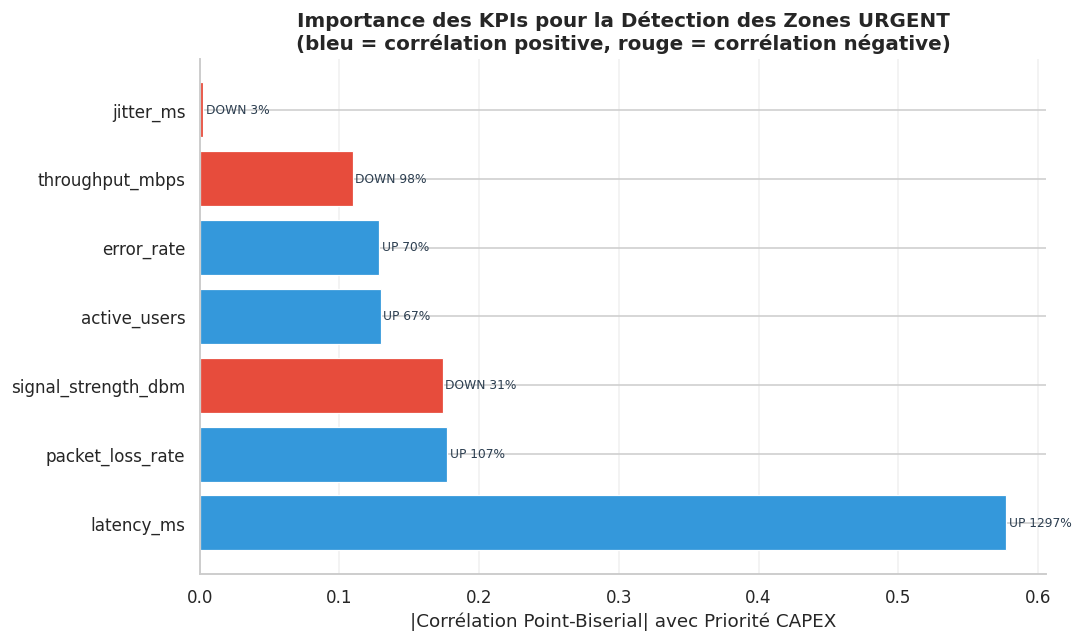

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

colors_bar = ['#e74c3c' if v < 0 else '#3498db' for v in results_df['PB_corr']]
bars = ax.barh(results_df['Feature'], results_df['PB_corr'].abs(),
               color=colors_bar, edgecolor='white', linewidth=0.8)

for bar, val, pct, feat in zip(bars, results_df['PB_corr'],
                                results_df['Pct_change'], results_df['Feature']):
    direction = 'UP' if val > 0 else 'DOWN'
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{direction} {abs(pct):.0f}%',
            va='center', fontsize=8, color='#2c3e50')

ax.set_xlabel('|Corrélation Point-Biserial| avec Priorité CAPEX')
ax.set_title('Importance des KPIs pour la Détection des Zones URGENT\n'
             '(bleu = corrélation positive, rouge = corrélation négative)',
             fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


## 9. Analyse de Corrélation entre KPIs


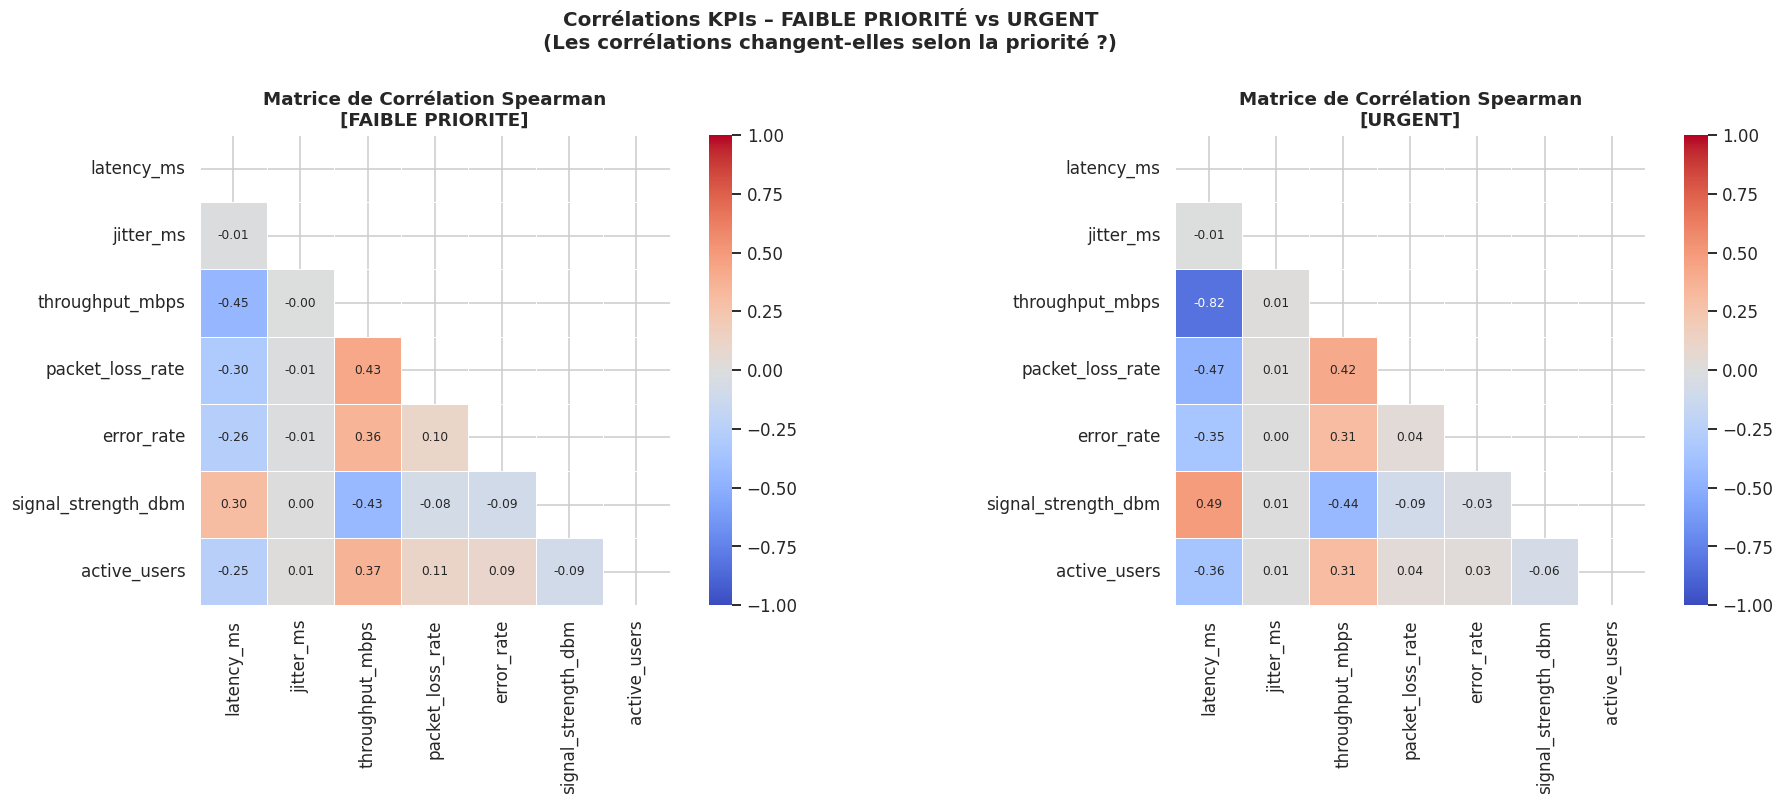

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for pclass, ax in zip([NORMAL_CLASS, URGENT_CLASS], axes):
    subset = train[train['priority'] == pclass][numeric_features]
    corr = subset.corr(method='spearman')
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, ax=ax, cmap='coolwarm', annot=True,
                fmt='.2f', linewidths=0.4, vmin=-1, vmax=1,
                annot_kws={'size': 8}, square=True)
    ax.set_title(f'Matrice de Corrélation Spearman\n[{pclass}]',
                 fontweight='bold', fontsize=12)

plt.suptitle('Corrélations KPIs – FAIBLE PRIORITÉ vs URGENT\n'
             '(Les corrélations changent-elles selon la priorité ?)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 10. Détection des Outliers (Méthode de Tukey)


In [ ]:
outlier_summary = []

for feat in numeric_features:
    Q1 = train[feat].quantile(0.25)
    Q3 = train[feat].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((train[feat] < lower) | (train[feat] > upper)).sum()
    pct_out = n_out / len(train) * 100

    # Taux d'URGENT parmi les outliers vs non-outliers
    is_outlier = (train[feat] < lower) | (train[feat] > upper)
    pct_urgent_outlier = (train.loc[is_outlier, 'priority'] == URGENT_CLASS).mean() * 100
    pct_urgent_normal  = (train.loc[~is_outlier, 'priority'] == URGENT_CLASS).mean() * 100

    outlier_summary.append({
        'Feature':              feat,
        'Q1':                   round(Q1, 3),
        'Q3':                   round(Q3, 3),
        'IQR':                  round(IQR, 3),
        'Borne_basse':          round(lower, 3),
        'Borne_haute':          round(upper, 3),
        'N_outliers':           n_out,
        'Pct_outliers':         round(pct_out, 2),
        'Pct_URGENT_outlier':   round(pct_urgent_outlier, 2),
        'Pct_URGENT_normal':    round(pct_urgent_normal, 2),
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values('Pct_outliers', ascending=False)
display(outlier_df.style
    .background_gradient(cmap='Reds', subset=['Pct_outliers'])
    .background_gradient(cmap='RdYlGn_r', subset=['Pct_URGENT_outlier'])
    .format({'Pct_outliers': '{:.2f}%', 'Pct_URGENT_outlier': '{:.1f}%',
             'Pct_URGENT_normal': '{:.1f}%'})
)


,Feature,Q1,Q3,IQR,Borne_basse,Borne_haute,N_outliers,Pct_outliers,Pct_URGENT_outlier,Pct_URGENT_normal
0,latency_ms,29.170000,69.330000,40.160000,-31.070000,129.570000,20055,10.03%,37.1%,2.6%
2,throughput_mbps,8.250000,72.410000,64.160000,-87.990000,168.650000,9171,4.59%,0.0%,6.3%
1,jitter_ms,8.200000,22.730000,14.530000,-13.595000,44.525000,0,0.00%,nan%,6.0%
3,packet_loss_rate,1.240000,3.750000,2.510000,-2.525000,7.515000,0,0.00%,nan%,6.0%
4,error_rate,0.503000,1.502000,0.999000,-0.995000,3.000000,0,0.00%,nan%,6.0%
5,signal_strength_dbm,-95.000000,-65.000000,30.000000,-140.000000,-20.000000,0,0.00%,nan%,6.0%
6,active_users,133.000000,377.000000,244.000000,-233.000000,743.000000,0,0.00%,nan%,6.0%


## 11. Évolution Temporelle des KPIs Critiques


Elle trace l'évolution de 4 KPIs clés sur toute la période, heure par heure, et surligne en rouge les créneaux où plus de 50% des mesures sont en zone URGENT — ce qui permet de voir si un pic de trafic coïncide avec une saturation du réseau ou une chute de débit.


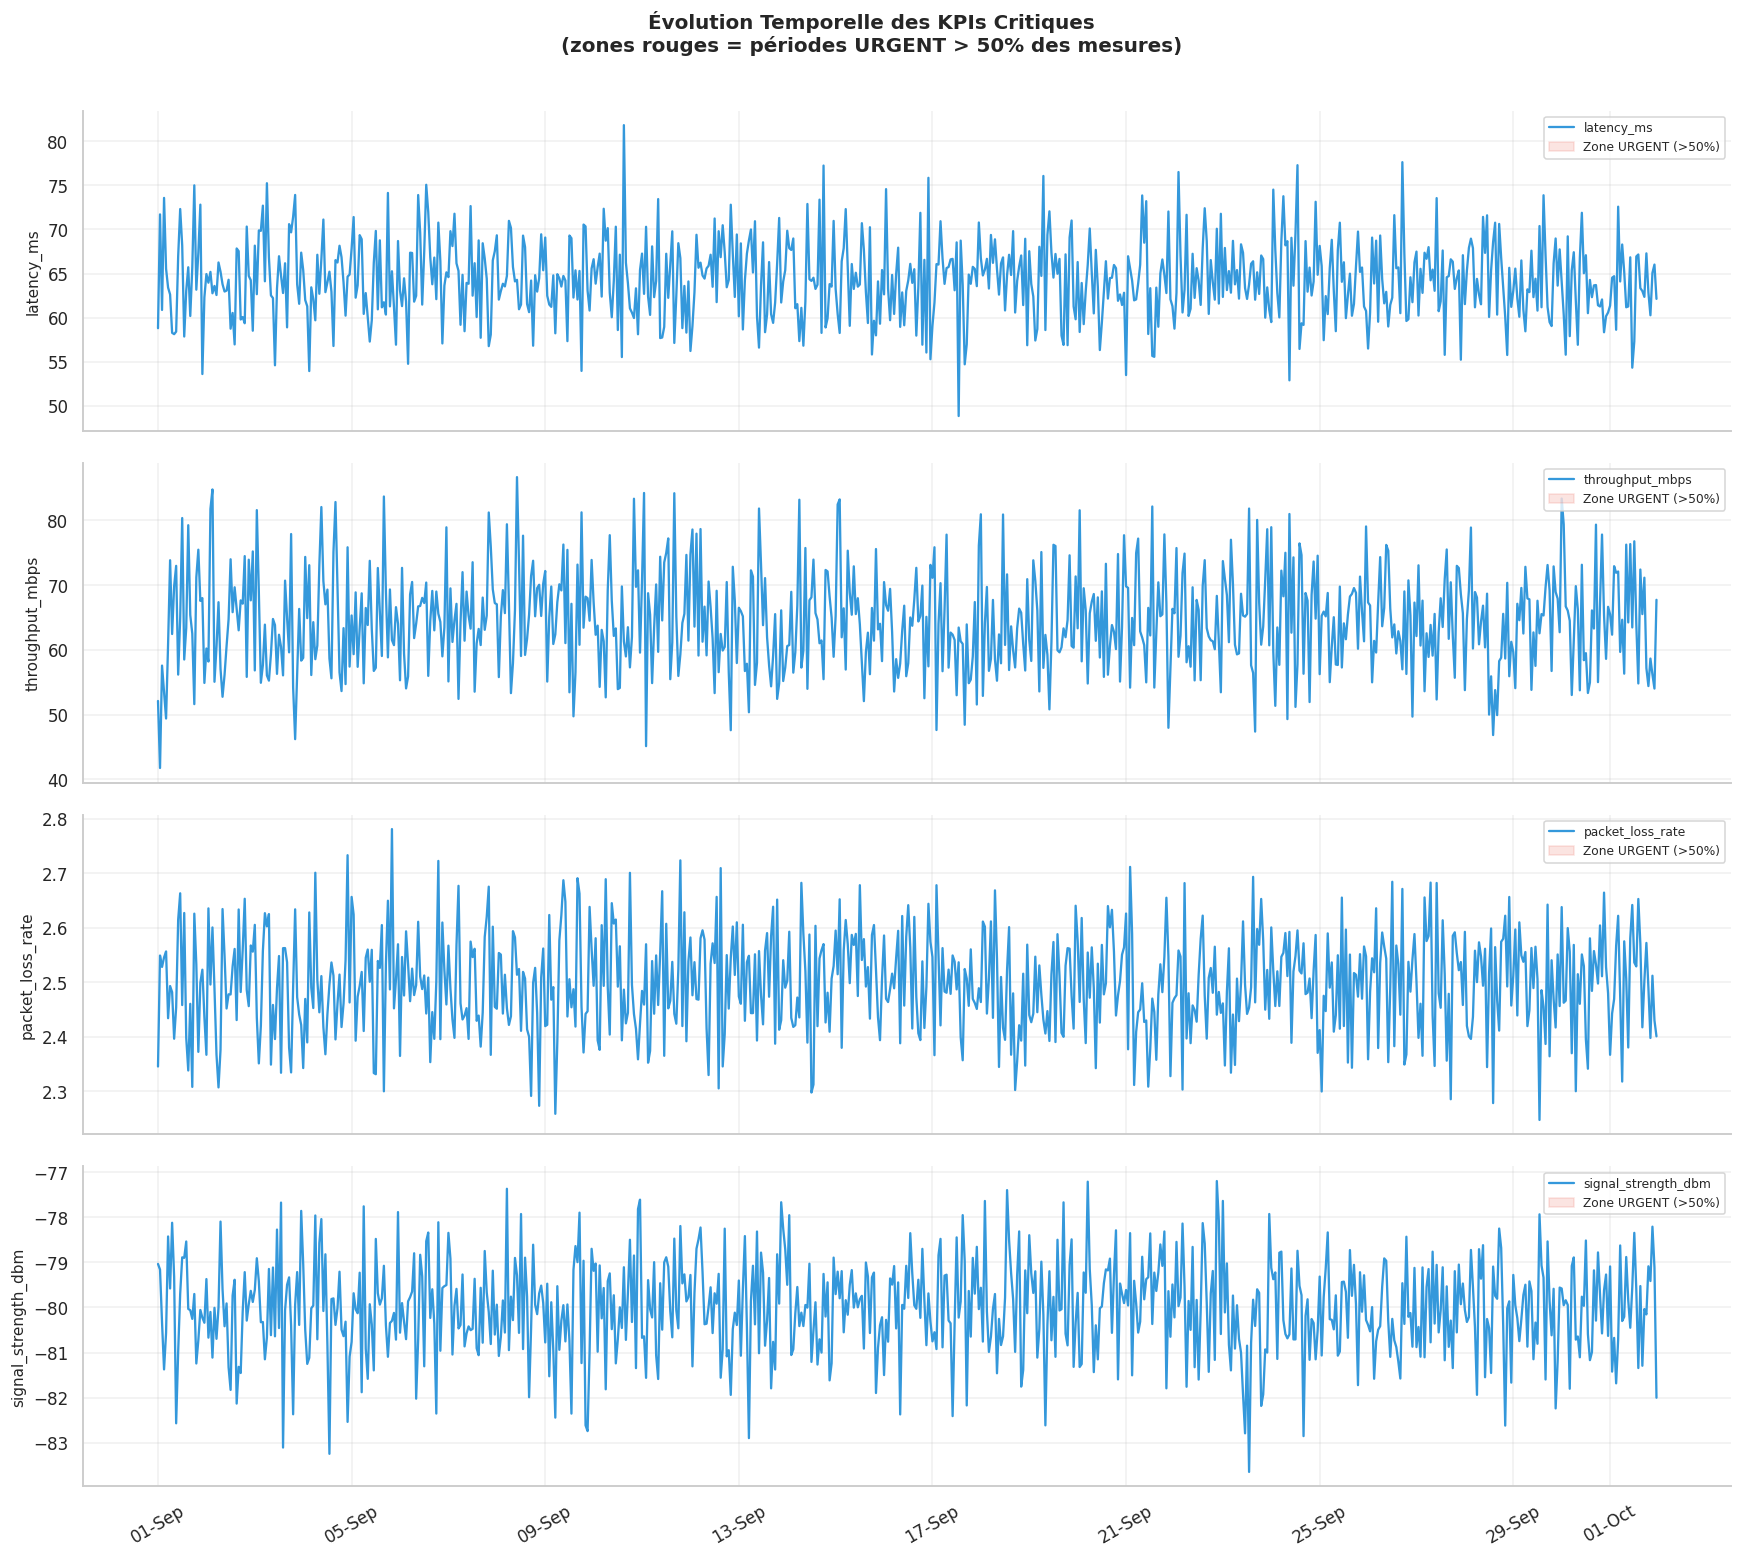

In [ ]:
train_ts = train.copy()
train_ts = train_ts.set_index(TIME_COL)

key_kpis = ['latency_ms', 'throughput_mbps', 'packet_loss_rate', 'signal_strength_dbm']

fig, axes = plt.subplots(len(key_kpis), 1, figsize=(16, 3.5 * len(key_kpis)), sharex=True)

for ax, feat in zip(axes, key_kpis):
    hourly_kpi = train_ts[feat].resample('1h').mean()
    hourly_urg = (train_ts['priority'] == URGENT_CLASS).resample('1h').mean()

    ax.plot(hourly_kpi.index, hourly_kpi.values, color='#3498db', lw=1.5, label=feat)

    # Surligner créneaux URGENT (> 50% des mesures)
    urgent_mask_ts = hourly_urg > 0.50
    ax.fill_between(hourly_kpi.index, hourly_kpi.min(), hourly_kpi.max(),
                    where=urgent_mask_ts, color='#e74c3c', alpha=0.15,
                    label='Zone URGENT (>50%)')

    ax.set_ylabel(feat, fontsize=10)
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=30)
plt.suptitle('Évolution Temporelle des KPIs Critiques\n'
             '(zones rouges = périodes URGENT > 50% des mesures)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


## 12. Profil par Zone – Identification des Zones Critiques


Elle calcule pour chaque ville son score CAPEX moyen et ses KPIs moyens, puis identifie automatiquement les zones critiques — celles dont le score dépasse la moyenne + un écart-type — pour savoir où investir en priorité avant que les clients ne soient impactés.


In [ ]:
agg_dict = {
    'n_obs':            ('capex_score', 'count'),
    'pct_urgent':       ('priority', lambda x: (x == URGENT_CLASS).mean() * 100),
    'avg_capex':        ('capex_score', 'mean'),
    'avg_latency':      ('latency_ms', 'mean'),
    'avg_throughput':   ('throughput_mbps', 'mean'),
    'avg_signal':       ('signal_strength_dbm', 'mean'),
    'avg_packet_loss':  ('packet_loss_rate', 'mean'),
    'avg_active_users': ('active_users', 'mean'),
}

city_profile = train.groupby(CITY_COL).agg(**agg_dict).reset_index()

# Identification zones critiques
threshold_critical = city_profile['avg_capex'].mean() + city_profile['avg_capex'].std()
city_profile['is_critical'] = city_profile['avg_capex'] >= threshold_critical

print(f'Seuil zone critique (mean + 1 std) : {threshold_critical:.2f}')
print(f'Zones critiques identifiées : {city_profile["is_critical"].sum()}')
display(city_profile.sort_values('avg_capex', ascending=False).style
    .background_gradient(cmap='RdYlGn_r', subset=['avg_capex', 'pct_urgent'])
    .format({'pct_urgent': '{:.1f}%', 'avg_capex': '{:.2f}',
             'avg_latency': '{:.1f} ms', 'avg_throughput': '{:.1f} Mbps'})
)


Seuil zone critique (mean + 1 std) : 51.58
Zones critiques identifiées : 2


,city,n_obs,pct_urgent,avg_capex,avg_latency,avg_throughput,avg_signal,avg_packet_loss,avg_active_users,is_critical
6,Ibadan,13314,6.0%,51.64,64.7 ms,63.4 Mbps,-80.131666,2.507105,255.386210,True
8,Jos,13443,6.1%,51.58,64.2 ms,64.7 Mbps,-79.994793,2.511698,254.637060,True
3,Benin City,13365,6.5%,51.57,65.4 ms,65.0 Mbps,-79.959596,2.501969,254.999701,False
7,Ilorin,13312,5.9%,51.56,63.1 ms,64.0 Mbps,-80.076923,2.522568,256.463416,False
11,Lagos,13323,6.0%,51.56,64.2 ms,64.9 Mbps,-80.187195,2.493169,254.991669,False
12,Onitsha,13013,6.3%,51.55,64.0 ms,62.9 Mbps,-79.911781,2.499288,256.779605,False
5,Enugu,13367,5.7%,51.54,64.7 ms,63.9 Mbps,-80.150221,2.482469,253.418194,False
0,Aba,13412,6.0%,51.52,65.5 ms,65.0 Mbps,-79.849687,2.505365,252.584178,False
4,Calabar,13536,6.1%,51.52,64.0 ms,63.5 Mbps,-79.850251,2.490186,254.752364,False
13,Port Harcourt,13327,5.7%,51.50,64.7 ms,62.5 Mbps,-79.897876,2.497230,252.096946,False


Elle représente chaque ville sous forme de point sur deux graphiques — latence vs score CAPEX, et débit vs score CAPEX — pour voir si les zones avec la pire connectivité sont aussi celles avec le plus fort besoin d'investissement, et identifier visuellement lesquelles nécessitent une intervention prioritaire.


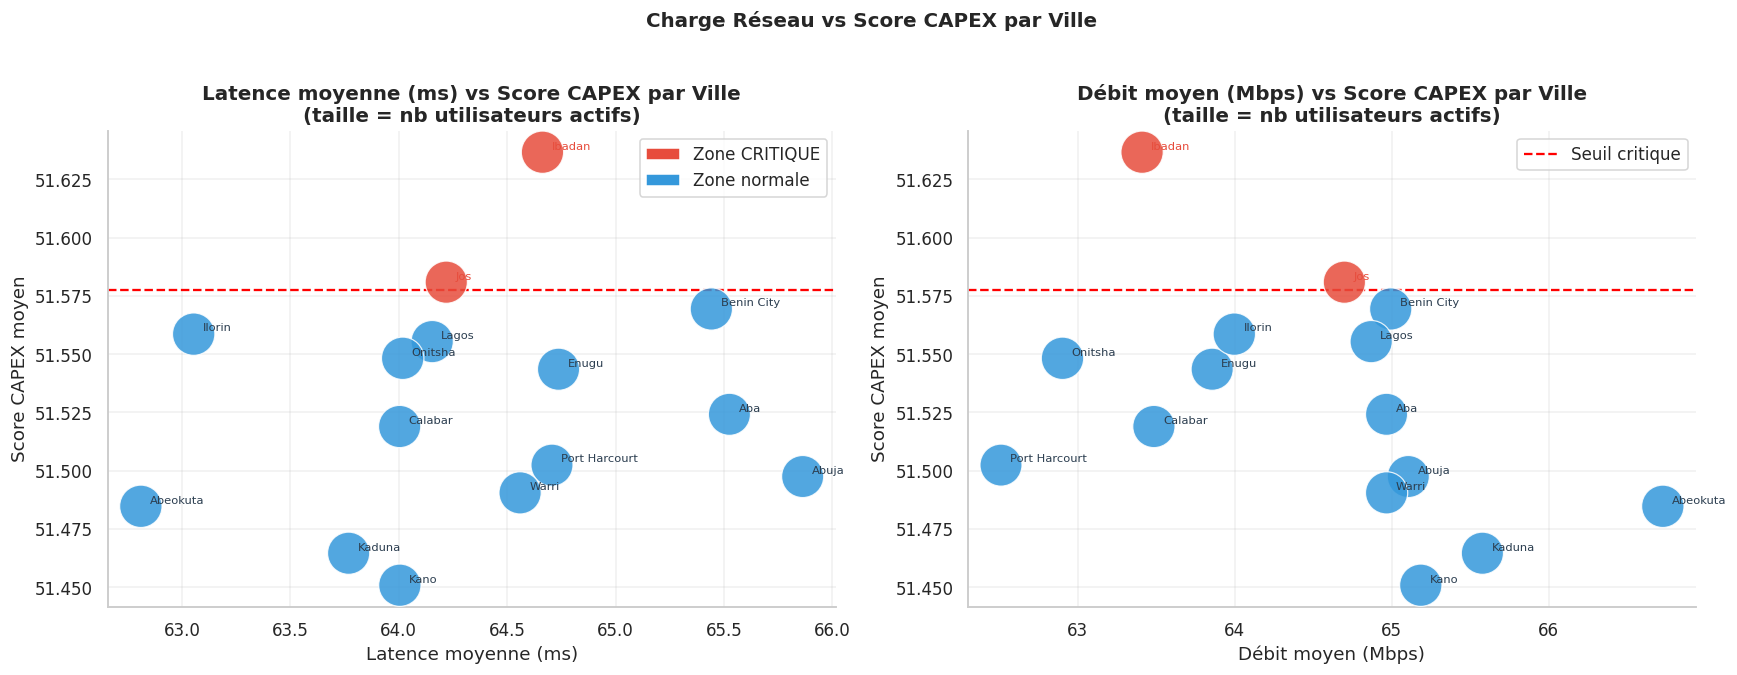

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (x_col, x_label) in zip(axes, [
    ('avg_latency',    'Latence moyenne (ms)'),
    ('avg_throughput', 'Débit moyen (Mbps)'),
]):
    colors_city = city_profile['is_critical'].map({True: '#e74c3c', False: '#3498db'})
    scatter = ax.scatter(
        city_profile[x_col], city_profile['avg_capex'],
        c=colors_city, s=city_profile['avg_active_users'] * 3,
        edgecolors='white', linewidth=0.8, alpha=0.85, zorder=3
    )
    for _, row in city_profile.iterrows():
        ax.annotate(row[CITY_COL],
                    (row[x_col], row['avg_capex']),
                    textcoords='offset points', xytext=(6, 2), fontsize=7.5,
                    color='#e74c3c' if row['is_critical'] else '#2c3e50')
    ax.axhline(threshold_critical, color='red', ls='--', lw=1.5, label='Seuil critique')
    ax.set_xlabel(x_label)
    ax.set_ylabel('Score CAPEX moyen')
    ax.set_title(f'{x_label} vs Score CAPEX par Ville\n(taille = nb utilisateurs actifs)')
    ax.legend()
    ax.grid(True, alpha=0.3)

from matplotlib.patches import Patch
legend_el = [Patch(facecolor='#e74c3c', label='Zone CRITIQUE'),
             Patch(facecolor='#3498db', label='Zone normale')]
axes[0].legend(handles=legend_el)

plt.suptitle('Charge Réseau vs Score CAPEX par Ville', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 13. Feature Engineering – Variables pour BO3


Elle crée 14 nouvelles variables à partir des données existantes pour enrichir le modèle : l'heure, le jour, si c'est un week-end ou une heure de pointe, le ratio latence/débit, le débit par utilisateur, l'efficacité réseau, et la classification du signal — car ces informations combinées permettent au modèle de mieux détecter les zones à investir.


In [ ]:
def engineer_features(df):
    df = df.copy()

    # === Temporel ===
    df['Hour']        = df[TIME_COL].dt.hour
    df['DayOfWeek']   = df[TIME_COL].dt.dayofweek
    df['IsWeekend']   = (df['DayOfWeek'] >= 5).astype(int)
    df['IsPeakHour']  = df['Hour'].isin([7, 8, 9, 17, 18, 19, 20]).astype(int)
    df['hour_sin']    = np.sin(2 * np.pi * df['Hour'] / 24)
    df['hour_cos']    = np.cos(2 * np.pi * df['Hour'] / 24)

    # === Réseau ===
    df['throughput_per_user']  = df['throughput_mbps'] / (df['active_users'] + 1)
    df['latency_jitter_ratio'] = df['latency_ms'] / (df['jitter_ms'] + 1)
    df['network_efficiency']   = df['throughput_mbps'] / (df['latency_ms'] + 1)
    df['packet_error_sum']     = df['packet_loss_rate'] + df['error_rate']

    # === Signal ===
    df['signal_quality'] = pd.cut(
        df['signal_strength_dbm'],
        bins=[-float('inf'), -100, -85, -70, float('inf')],
        labels=[0, 1, 2, 3]
    ).astype(float)

    # === Encodage réseau ===
    enc = OrdinalEncoder(categories=[['2G', '3G', '4G', '5G']])
    df['network_type_num'] = enc.fit_transform(df[['network_type']]).astype(int)

    # === Zone-level features (basées uniquement sur les KPIs bruts, sans capex_score) ===
    # ⚠️ city_avg_capex et capex_vs_city_avg SUPPRIMÉES : dérivées directement du score cible
    # On utilise à la place des agrégats de KPIs bruts par ville (pas de leakage)
    df['city_avg_latency']    = df.groupby(CITY_COL)['latency_ms'].transform('mean')
    df['city_avg_throughput'] = df.groupby(CITY_COL)['throughput_mbps'].transform('mean')
    df['city_avg_packet_loss']= df.groupby(CITY_COL)['packet_loss_rate'].transform('mean')

    return df

train_fe = engineer_features(train)

new_features = ['IsPeakHour', 'IsWeekend', 'hour_sin', 'hour_cos',
                'throughput_per_user', 'latency_jitter_ratio', 'network_efficiency',
                'packet_error_sum', 'signal_quality', 'network_type_num',
                'city_avg_latency', 'city_avg_throughput', 'city_avg_packet_loss']
# ✅ city_avg_capex et capex_vs_city_avg supprimées (data leakage : dérivées de capex_score)

print(f'Nouvelles features créées : {len(new_features)}')
display(train_fe[new_features].describe().round(3))


Nouvelles features créées : 13


,IsPeakHour,IsWeekend,hour_sin,hour_cos,throughput_per_user,latency_jitter_ratio,network_efficiency,packet_error_sum,signal_quality,network_type_num,city_avg_latency,city_avg_throughput,city_avg_packet_loss
count,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000,200000.000
mean,0.292,0.259,-0.001,0.001,0.505,6.133,3.353,3.500,1.720,1.701,64.368,64.487,2.498
std,0.455,0.438,0.708,0.707,1.905,10.834,11.658,1.557,1.101,0.638,0.821,1.071,0.011
min,0.000,0.000,-1.000,-1.000,0.000,0.163,0.000,0.016,0.000,0.000,62.811,62.513,2.480
25%,0.000,0.000,-0.707,-0.707,0.039,1.619,0.088,2.249,1.000,1.000,64.004,63.486,2.490
50%,0.000,0.000,0.000,0.000,0.154,2.952,1.052,3.503,2.000,2.000,64.219,64.869,2.499
75%,1.000,1.000,0.707,0.707,0.345,6.284,2.016,4.749,3.000,2.000,64.737,65.106,2.507
max,1.000,1.000,1.000,1.000,85.854,246.433,165.879,6.997,3.000,3.000,65.863,66.726,2.523


Elle vérifie si les nouvelles variables créées sont vraiment utiles pour prédire la priorité CAPEX — les variables binaires (0/1) sont testées avec Chi2, les variables continues avec Mann-Whitney — et affiche lesquelles ont un impact statistiquement significatif (p_value < 0.05).


In [ ]:
y_bin = (train_fe['priority'] == URGENT_CLASS).astype(int)

fe_results = []
for feat in new_features:
    if train_fe[feat].nunique() <= 4:
        ct = pd.crosstab(train_fe[feat], train_fe['priority'])
        chi2_stat, p, _, _ = chi2_contingency(ct)
        fe_results.append({'Feature': feat, 'Test': 'Chi2',
                            'Stat': round(chi2_stat, 3), 'p_value': round(p, 6),
                            'Significatif': 'OUI' if p < 0.05 else 'NON'})
    else:
        urgent_vals = train_fe.loc[train_fe['priority'] == URGENT_CLASS, feat].dropna()
        normal_vals = train_fe.loc[train_fe['priority'] == NORMAL_CLASS, feat].dropna()
        try:
            stat, p = mannwhitneyu(normal_vals, urgent_vals, alternative='two-sided')
        except Exception:
            stat, p = np.nan, np.nan
        fe_results.append({'Feature': feat, 'Test': 'Mann-Whitney',
                            'Stat': round(stat, 3), 'p_value': round(p, 6),
                            'Significatif': 'OUI' if p < 0.05 else 'NON'})

fe_df = pd.DataFrame(fe_results).sort_values('p_value')
display(fe_df.style
    .applymap(lambda v: 'background-color: #d5f5e3' if v == 'OUI' else
              'background-color: #fadbd8' if v == 'NON' else '',
              subset=['Significatif'])
    .format({'p_value': '{:.6f}'})
)


,Feature,Test,Stat,p_value,Significatif
7,packet_error_sum,Mann-Whitney,9387919.000000,0.000000,OUI
6,network_efficiency,Mann-Whitney,68602385.500000,0.000000,OUI
5,latency_jitter_ratio,Mann-Whitney,2834227.500000,0.000000,OUI
4,throughput_per_user,Mann-Whitney,69087262.500000,0.000000,OUI
9,network_type_num,Chi2,131587.111000,0.000000,OUI
8,signal_quality,Chi2,7811.370000,0.000000,OUI
11,city_avg_throughput,Mann-Whitney,35308984.000000,0.022087,OUI
3,hour_cos,Mann-Whitney,35040953.500000,0.147449,NON
0,IsPeakHour,Chi2,2.389000,0.302895,NON
10,city_avg_latency,Mann-Whitney,34361180.000000,0.497811,NON


## 14. Synthèse – Recommandations BO3


In [ ]:
print('=' * 65)
print(' ODS3 / BO3 – CAPEX Scoring & Smart Zone Ranking')
print('=' * 65)

n_urgent = (train['priority'] == 'URGENT').sum()
n_moyen  = (train['priority'] == 'MOYEN TERME').sum()
n_faible = (train['priority'] == 'FAIBLE PRIORITE').sum()
n_critical_cities = city_profile['is_critical'].sum()
critical_cities = city_profile[city_profile['is_critical']][CITY_COL].tolist()

print(f'''
DATASET
  {len(train):,} observations | {train[CITY_COL].nunique()} villes
  {train[OP_COL].nunique()} operateurs | {train[NET_COL].nunique()} types de reseau
  URGENT : {n_urgent:,} ({n_urgent/len(train)*100:.1f}%) | MOYEN TERME : {n_moyen:,} ({n_moyen/len(train)*100:.1f}%) | FAIBLE : {n_faible:,} ({n_faible/len(train)*100:.1f}%)

ZONES CRITIQUES IDENTIFIEES ({n_critical_cities} villes)
  -> {', '.join(critical_cities)}

KPIs LES PLUS DISCRIMINANTS (Point-Biserial)
  -> {results_df.head(3)['Feature'].tolist()}

PATTERNS TEMPORELS
  -> Score CAPEX le plus eleve : heure et jour avec capex le plus haut
  -> Heure de pointe (7h-9h, 17h-20h) = stress reseau accru

RECOMMANDATIONS BO3
  1. Zones URGENT : deploiement 4G/5G immediat, remplacement infra 2G/3G
  2. Zones MOYEN TERME : planification CAPEX N+1, optimisation configuration
  3. Zones FAIBLE : maintenance preventive, monitoring QoS trimestriel
''')


 ODS3 / BO3 – CAPEX Scoring & Smart Zone Ranking

DATASET
  200,000 observations | 15 villes
  4 operateurs | 4 types de reseau
  URGENT : 12,048 (6.0%) | MOYEN TERME : 182,212 (91.1%) | FAIBLE : 5,740 (2.9%)

ZONES CRITIQUES IDENTIFIEES (2 villes)
  -> Ibadan, Jos

KPIs LES PLUS DISCRIMINANTS (Point-Biserial)
  -> ['latency_ms', 'packet_loss_rate', 'signal_strength_dbm']

PATTERNS TEMPORELS
  -> Score CAPEX le plus eleve : heure et jour avec capex le plus haut
  -> Heure de pointe (7h-9h, 17h-20h) = stress reseau accru

RECOMMANDATIONS BO3
  1. Zones URGENT : deploiement 4G/5G immediat, remplacement infra 2G/3G
  2. Zones MOYEN TERME : planification CAPEX N+1, optimisation configuration
  3. Zones FAIBLE : maintenance preventive, monitoring QoS trimestriel



## 15. Prochaines Étapes – Pipeline Modélisation BO3


Elle prépare les données pour le modèle, équilibre le dataset avec SMOTE si nécessaire, puis compare trois stratégies (class_weight, SMOTE, seuil adapté) en mesurant l'AUC et le Recall — et choisit automatiquement la meilleure pour entraîner le modèle final de scoring CAPEX.


---
# 🧠 Deep Learning – CAPEX Scoring & Zone Ranking (BO3 / ODS3)

> Remplacement des modèles classiques (LightGBM / RF / LogReg) par une suite **deep learning** :
> - **MLP (Multi-Layer Perceptron)** – baseline réseau de neurones dense
> - **TabNet** – architecture Transformer adaptée aux données tabulaires
> - **Autoencoder + MLP** – scoring anomalie non-supervisé combiné à la classification
>
> **Objectif ODS3/BO3** : CAPEX Scoring & Zone Ranking – Investir aux bons endroits


## 0-DL. Installation des dépendances Deep Learning

In [ ]:
!pip install pytorch-tabnet imbalanced-learn -q
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTE
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED   = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
print(f"Device utilisé : {DEVICE}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.1 MB/s eta 0:00:00
Device utilisé : cuda


## 1-DL. Préparation des données pour le Deep Learning

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

le_city = LabelEncoder()
le_op   = LabelEncoder()
if f"{CITY_COL}_enc" not in train_fe.columns:
    train_fe[f"{CITY_COL}_enc"] = le_city.fit_transform(train_fe[CITY_COL])
    train_fe[f"{OP_COL}_enc"]   = le_op.fit_transform(train_fe[OP_COL])

# Colonnes à exclure explicitement
# ⚠️  capex_score + colonnes intermédiaires de sa construction = data leakage direct
EXCLUDE_COLS = [
    TIME_COL, "priority", "Date", "DayName",
    CITY_COL, OP_COL, NET_COL,
    "capex_score",          # ← cible synthétique → leakage
    "latency_capped",       # ← intermédiaire de capex_score
    "throughput_capped",    # ← intermédiaire de capex_score
    "city_avg_capex",       # ← moyenne de capex_score par ville → leakage
    "capex_vs_city_avg",    # ← écart à capex_score → leakage
    "proba_urgent_dl",      # ← prédictions (si re-run)
    "pred_urgent_dl",
]

# ✅ CORRECTION : ne garder QUE les colonnes numériques (int/float)
feature_cols = [
    c for c in train_fe.columns
    if c not in EXCLUDE_COLS
    and c in train_fe.columns
    and train_fe[c].dtype in [np.float64, np.float32, np.int64, np.int32, np.uint8, np.bool_]
]

# ── Vérification anti-leakage ──
leaky_cols = [c for c in feature_cols if 'capex' in c.lower()]
if leaky_cols:
    print(f"⚠️  ATTENTION leakage détecté : {leaky_cols}")
    feature_cols = [c for c in feature_cols if c not in leaky_cols]
    print(f"✅ Colonnes leaky retirées automatiquement")
else:
    print("✅ Aucun leakage détecté dans feature_cols")

print(f"Colonnes non-numériques ignorées : {[c for c in train_fe.columns if c not in EXCLUDE_COLS and train_fe[c].dtype == object]}")
print(f"Features retenues : {len(feature_cols)}")
print(feature_cols)

X = train_fe[feature_cols].fillna(0).values.astype(np.float32)
y = (train_fe["priority"] == URGENT_CLASS).astype(int).values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# SMOTE pour équilibrer les classes
sm = SMOTE(random_state=SEED)
X_sm, y_sm = sm.fit_resample(X_train, y_train)

# Normalisation
scaler = StandardScaler()
X_sm_sc    = scaler.fit_transform(X_sm).astype(np.float32)
X_train_sc = scaler.transform(X_train).astype(np.float32)
X_val_sc   = scaler.transform(X_val).astype(np.float32)

print(f"\nTrain (avant SMOTE) : {X_train.shape[0]:,} | Val : {X_val.shape[0]:,}")
print(f"Train (après SMOTE) : {X_sm.shape[0]:,} | Taux URGENT : {y_sm.mean()*100:.1f}%")

✅ Aucun leakage détecté dans feature_cols
Colonnes non-numériques ignorées : ['metric_id', 'tower_id']
Features retenues : 24
['latency_ms', 'jitter_ms', 'throughput_mbps', 'packet_loss_rate', 'error_rate', 'signal_strength_dbm', 'active_users', 'Hour', 'DayOfWeek', 'IsWeekend', 'IsPeakHour', 'hour_sin', 'hour_cos', 'throughput_per_user', 'latency_jitter_ratio', 'network_efficiency', 'packet_error_sum', 'signal_quality', 'network_type_num', 'city_avg_latency', 'city_avg_throughput', 'city_avg_packet_loss', 'city_enc', 'operator_enc']

Train (avant SMOTE) : 160,000 | Val : 40,000
Train (après SMOTE) : 300,724 | Taux URGENT : 50.0%


## 2-DL. Modèle 1 – MLP (Multi-Layer Perceptron)

> Architecture réseau dense avec BatchNorm, Dropout et activation GELU – optimisé pour les données tabulaires réseau.


In [ ]:
class CapexMLP(nn.Module):
    def __init__(self, input_dim, hidden=[256, 128, 64], dropout=0.3):
        super().__init__()
        layers = []
        in_d = input_dim
        for h in hidden:
            layers += [
                nn.Linear(in_d, h),
                nn.BatchNorm1d(h),
                nn.GELU(),
                nn.Dropout(dropout)
            ]
            in_d = h
        layers.append(nn.Linear(in_d, 1))
        layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_mlp(X_tr, y_tr, X_v, y_v, epochs=50, batch=512, lr=1e-3):
    model = CapexMLP(X_tr.shape[1]).to(DEVICE)
    pos_w = torch.tensor([(y_tr == 0).sum() / (y_tr == 1).sum()],
                         dtype=torch.float32).to(DEVICE)
    criterion = nn.BCELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    Xt = torch.tensor(X_tr).to(DEVICE)
    yt = torch.tensor(y_tr, dtype=torch.float32).to(DEVICE)
    ds = TensorDataset(Xt, yt)
    dl = DataLoader(ds, batch_size=batch, shuffle=True)

    Xv = torch.tensor(X_v).to(DEVICE)

    train_losses, val_aucs = [], []
    best_auc, best_state = 0, None

    for ep in range(epochs):
        model.train()
        ep_loss = 0
        for xb, yb in dl:
            optimizer.zero_grad()
            pred = model(xb)
            # Weighted BCE
            w = torch.where(yb == 1, pos_w.squeeze(), torch.ones(1).to(DEVICE))
            loss = (w * nn.functional.binary_cross_entropy(pred, yb, reduction="none")).mean()
            loss.backward()
            optimizer.step()
            ep_loss += loss.item()
        scheduler.step()

        model.eval()
        with torch.no_grad():
            proba_v = model(Xv).cpu().numpy()
        auc_v = roc_auc_score(y_v, proba_v)
        train_losses.append(ep_loss / len(dl))
        val_aucs.append(auc_v)
        if auc_v > best_auc:
            best_auc = auc_v
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if (ep + 1) % 10 == 0:
            print(f"  Epoch {ep+1:3d}/{epochs} | Loss={ep_loss/len(dl):.4f} | AUC-Val={auc_v:.4f}")

    model.load_state_dict(best_state)
    return model, train_losses, val_aucs, best_auc


print("Entraînement MLP...")
mlp_model, mlp_losses, mlp_aucs, mlp_best_auc = train_mlp(
    X_sm_sc, y_sm, X_val_sc, y_val
)

mlp_model.eval()
with torch.no_grad():
    mlp_proba = mlp_model(torch.tensor(X_val_sc).to(DEVICE)).cpu().numpy()
print(f"MLP – Meilleur AUC val : {mlp_best_auc:.4f}")


Entraînement MLP...
  Epoch  10/50 | Loss=0.0139 | AUC-Val=0.9999
  Epoch  20/50 | Loss=0.0116 | AUC-Val=0.9999
  Epoch  30/50 | Loss=0.0099 | AUC-Val=0.9999
  Epoch  40/50 | Loss=0.0093 | AUC-Val=0.9999
  Epoch  50/50 | Loss=0.0087 | AUC-Val=1.0000
MLP – Meilleur AUC val : 1.0000


## 3-DL. Modèle 2 – TabNet

> TabNet utilise un mécanisme d'attention séquentielle pour sélectionner automatiquement les features les plus pertinentes à chaque étape de décision — particulièrement adapté aux données réseau avec de nombreux KPIs corrélés.


In [ ]:
print("Entraînement TabNet...")

tabnet = TabNetClassifier(
    n_d=32, n_a=32,
    n_steps=5,
    gamma=1.5,
    n_independent=2, n_shared=2,
    momentum=0.02,
    mask_type="sparsemax",
    seed=SEED,
    verbose=0,
    device_name=DEVICE,
)

tabnet.fit(
    X_sm_sc, y_sm,
    eval_set=[(X_val_sc, y_val)],
    eval_metric=["auc"],
    max_epochs=100,
    patience=15,
    batch_size=1024,
    virtual_batch_size=128,
    num_workers=0,
    drop_last=False,
)

tabnet_proba = tabnet.predict_proba(X_val_sc)[:, 1]
tabnet_auc   = roc_auc_score(y_val, tabnet_proba)
print(f"TabNet – AUC val : {tabnet_auc:.4f}")


Entraînement TabNet...

Early stopping occurred at epoch 48 with best_epoch = 33 and best_val_0_auc = 0.99999
TabNet – AUC val : 1.0000


## 4-DL. Modèle 3 – Autoencoder + MLP (Anomaly-Aware Scoring)

> L'Autoencoder est entraîné uniquement sur les zones **NON-URGENT** pour apprendre la représentation normale du réseau.
> Les zones URGENT auront un **erreur de reconstruction élevée** → signal d'anomalie utilisé comme feature supplémentaire dans un MLP final.


In [ ]:
# ── Autoencoder ──────────────────────────────────────────────
class NetworkAutoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128), nn.GELU(), nn.BatchNorm1d(128),
            nn.Linear(128, 64),        nn.GELU(), nn.BatchNorm1d(64),
            nn.Linear(64, latent_dim), nn.GELU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.GELU(), nn.BatchNorm1d(64),
            nn.Linear(64, 128),        nn.GELU(), nn.BatchNorm1d(128),
            nn.Linear(128, input_dim)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))
    def encode(self, x):
        return self.encoder(x)
    def reconstruction_error(self, x):
        with torch.no_grad():
            recon = self.forward(x)
        return ((x - recon) ** 2).mean(dim=1)


# Entraîner sur les zones normales uniquement
X_normal_sc = X_train_sc[y_train == 0]

ae = NetworkAutoencoder(X_train_sc.shape[1]).to(DEVICE)
ae_optim = optim.AdamW(ae.parameters(), lr=5e-4, weight_decay=1e-5)
ae_criterion = nn.MSELoss()

Xn = torch.tensor(X_normal_sc).to(DEVICE)
ae_ds = TensorDataset(Xn)
ae_dl = DataLoader(ae_ds, batch_size=512, shuffle=True)

print("Entraînement Autoencoder (zones normales)...")
ae_losses = []
for ep in range(60):
    ae.train()
    ep_loss = 0
    for (xb,) in ae_dl:
        ae_optim.zero_grad()
        recon = ae(xb)
        loss  = ae_criterion(recon, xb)
        loss.backward()
        ae_optim.step()
        ep_loss += loss.item()
    ae_losses.append(ep_loss / len(ae_dl))
    if (ep + 1) % 15 == 0:
        print(f"  Epoch {ep+1:3d}/60 | AE Loss={ep_loss/len(ae_dl):.6f}")

ae.eval()

# Calcul des erreurs de reconstruction comme feature anomalie
def get_recon_error(X_np):
    Xt = torch.tensor(X_np).to(DEVICE)
    return ae.reconstruction_error(Xt).cpu().numpy()

recon_train = get_recon_error(X_sm_sc).reshape(-1, 1)
recon_val   = get_recon_error(X_val_sc).reshape(-1, 1)

# Concaténer la feature anomalie
X_sm_ae  = np.hstack([X_sm_sc,  recon_train])
X_val_ae = np.hstack([X_val_sc, recon_val])

print("Entraînement MLP + Anomaly Feature...")
ae_mlp_model, _, _, ae_mlp_best_auc = train_mlp(
    X_sm_ae.astype(np.float32), y_sm, X_val_ae.astype(np.float32), y_val
)
ae_mlp_model.eval()
with torch.no_grad():
    ae_mlp_proba = ae_mlp_model(torch.tensor(X_val_ae.astype(np.float32)).to(DEVICE)).cpu().numpy()
print(f"Autoencoder+MLP – AUC val : {ae_mlp_best_auc:.4f}")


Entraînement Autoencoder (zones normales)...
  Epoch  15/60 | AE Loss=0.012859
  Epoch  30/60 | AE Loss=0.009875
  Epoch  45/60 | AE Loss=0.007299
  Epoch  60/60 | AE Loss=0.006417
Entraînement MLP + Anomaly Feature...
  Epoch  10/50 | Loss=0.0136 | AUC-Val=0.9999
  Epoch  20/50 | Loss=0.0115 | AUC-Val=0.9999
  Epoch  30/50 | Loss=0.0094 | AUC-Val=0.9999
  Epoch  40/50 | Loss=0.0091 | AUC-Val=0.9999
  Epoch  50/50 | Loss=0.0087 | AUC-Val=0.9999
Autoencoder+MLP – AUC val : 0.9999


## 5-DL. Comparaison des Modèles Deep Learning

  MLP                       AUC=1.0000 | Recall=0.9846 | F1=0.9871
  TabNet                    AUC=1.0000 | Recall=0.9913 | F1=0.9923
  Autoencoder + MLP         AUC=0.9999 | Recall=0.9900 | F1=0.9864
Tableau comparatif :


,Modele,AUC-ROC,Recall,F1,Seuil optimal
0,MLP,1.0000,0.9846,0.9871,0.860000
1,TabNet,1.0000,0.9913,0.9923,0.840000
2,Autoencoder + MLP,0.9999,0.9900,0.9864,0.640000


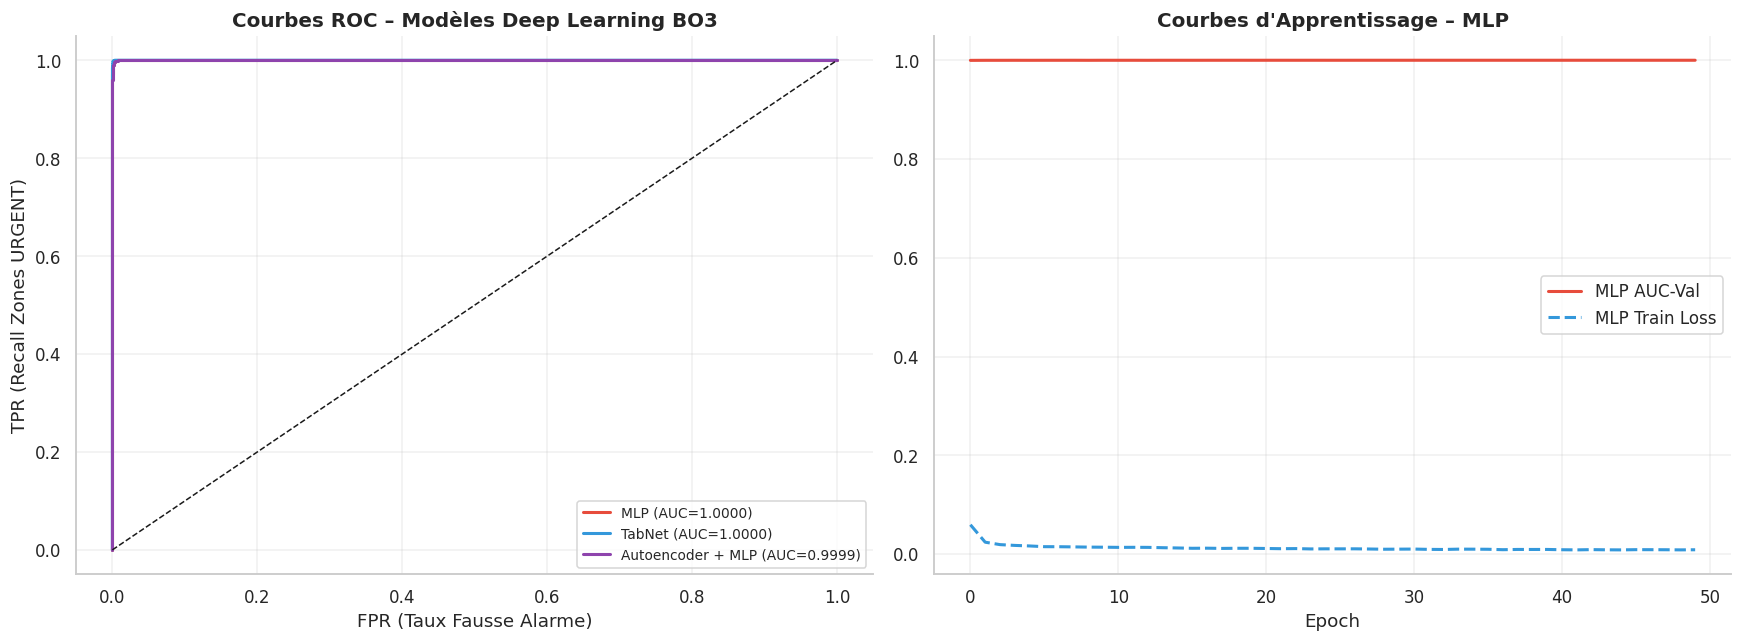

In [ ]:
from sklearn.metrics import roc_curve, auc as sk_auc
from matplotlib.patches import Patch

# Seuil optimal pour chaque modèle
def best_threshold(y_true, y_proba):
    thresholds = np.arange(0.1, 0.9, 0.02)
    return max(thresholds, key=lambda t: f1_score(y_true, (y_proba >= t).astype(int)))

models_dl = {
    "MLP": mlp_proba,
    "TabNet": tabnet_proba,
    "Autoencoder + MLP": ae_mlp_proba,
}

results_dl = []
trained_dl = {}
for name, proba in models_dl.items():
    thresh = best_threshold(y_val, proba)
    pred   = (proba >= thresh).astype(int)
    auc_s  = roc_auc_score(y_val, proba)
    rec_s  = recall_score(y_val, pred)
    f1_s   = f1_score(y_val, pred)
    results_dl.append({"Modele": name, "AUC-ROC": round(auc_s, 4),
                       "Recall": round(rec_s, 4), "F1": round(f1_s, 4),
                       "Seuil optimal": round(thresh, 2)})
    trained_dl[name] = {"proba": proba, "pred": pred, "thresh": thresh, "auc": auc_s}
    print(f"  {name:<25} AUC={auc_s:.4f} | Recall={rec_s:.4f} | F1={f1_s:.4f}")

results_df_dl = pd.DataFrame(results_dl).sort_values("AUC-ROC", ascending=False)
print("Tableau comparatif :")
display(results_df_dl.style
    .background_gradient(cmap="Greens", subset=["AUC-ROC", "Recall", "F1"])
    .format({"AUC-ROC": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"})
    .set_caption("Comparaison modèles Deep Learning – CAPEX Scoring BO3")
)

# ── Courbes ROC ──────────────────────────────────────────────
colors_roc = ["#e74c3c", "#3498db", "#8e44ad"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for (name, res), c in zip(trained_dl.items(), colors_roc):
    fpr, tpr, _ = roc_curve(y_val, res["proba"])
    axes[0].plot(fpr, tpr, lw=2, color=c,
                 label=f"{name} (AUC={res['auc']:.4f})")
axes[0].plot([0,1],[0,1], "k--", lw=1)
axes[0].set_title("Courbes ROC – Modèles Deep Learning BO3", fontweight="bold")
axes[0].set_xlabel("FPR (Taux Fausse Alarme)")
axes[0].set_ylabel("TPR (Recall Zones URGENT)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Training curves MLP ──────────────────────────────────────
axes[1].plot(mlp_aucs, color="#e74c3c", lw=2, label="MLP AUC-Val")
axes[1].plot(mlp_losses, color="#3498db", lw=2, linestyle="--", label="MLP Train Loss")
axes[1].set_title("Courbes d'Apprentissage – MLP", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6-DL. Analyse du Meilleur Modèle Deep Learning

Meilleur modèle DL : MLP | AUC=1.0000 | Seuil=0.86

--- Rapport de classification ---
              precision    recall  f1-score   support

  Non-Urgent       1.00      1.00      1.00     37590
      URGENT       0.99      0.98      0.99      2410

    accuracy                           1.00     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       1.00      1.00      1.00     40000



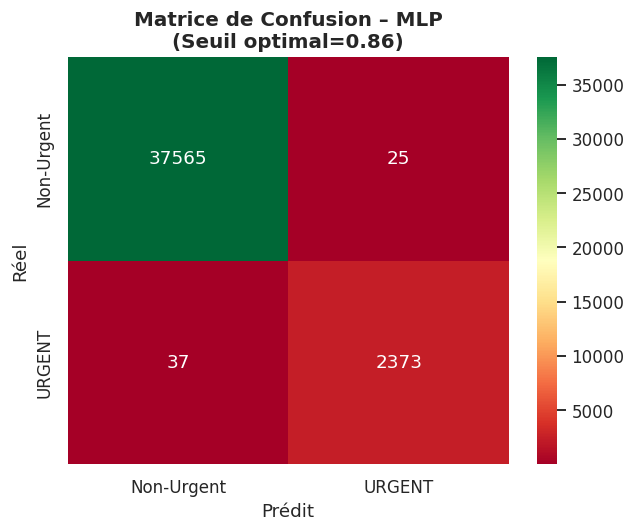

In [ ]:
# Récupération du meilleur modèle DL et de son seuil optimal
best_dl_name = results_df_dl.iloc[0]['Modele']
best_dl_res  = trained_dl[best_dl_name]
print(f"Meilleur modèle DL : {best_dl_name} | AUC={best_dl_res['auc']:.4f} | Seuil={best_dl_res['thresh']:.2f}")

# Rapport de classification du meilleur modèle
print('\n--- Rapport de classification ---')
print(classification_report(y_val, best_dl_res['pred'],
      target_names=['Non-Urgent', 'URGENT']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_val, best_dl_res['pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='RdYlGn',
            xticklabels=['Non-Urgent', 'URGENT'],
            yticklabels=['Non-Urgent', 'URGENT'], ax=ax)
ax.set_title(f'Matrice de Confusion – {best_dl_name}\n'
             f'(Seuil optimal={best_dl_res["thresh"]:.2f})',
             fontweight='bold')
ax.set_xlabel('Prédit')
ax.set_ylabel('Réel')
plt.tight_layout()
plt.show()


## 7-DL. Feature Importance – TabNet Attention Masks

> TabNet fournit une importance native via ses **masques d'attention** – contrairement aux arbres, elle reflète l'attention accordée à chaque feature à chaque étape de décision.


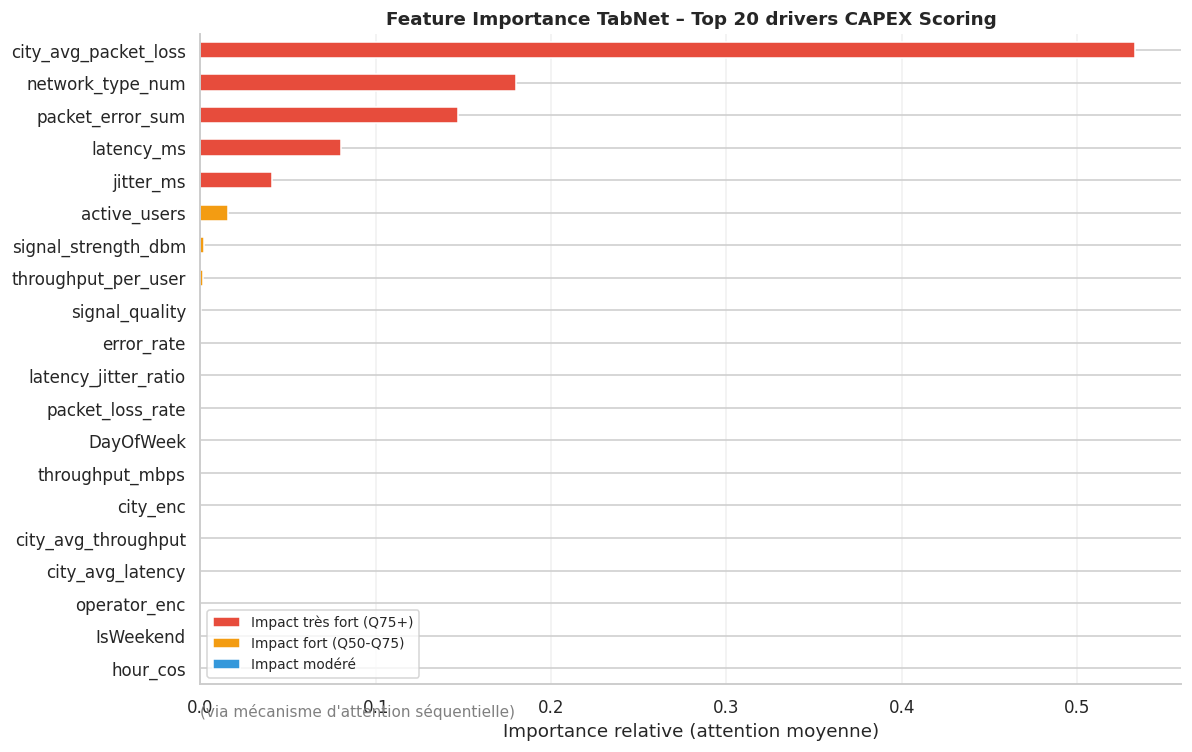

Top 5 features selon TabNet :
  city_avg_packet_loss           0.5328
  network_type_num               0.1802
  packet_error_sum               0.1468
  latency_ms                     0.0799
  jitter_ms                      0.0410


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Série des importances
tn_imp = pd.Series(
    tabnet.feature_importances_,
    index=feature_cols
).sort_values(ascending=True)

# Top 20
top20 = tn_imp.tail(20)

# Couleurs selon quantiles
q50 = top20.quantile(0.50)
q75 = top20.quantile(0.75)
colors_fi = [
    "#e74c3c" if v > q75 else
    "#f39c12" if v > q50 else
    "#3498db"
    for v in top20.values
]

# Plot horizontal
fig, ax = plt.subplots(figsize=(11, 7))
top20.plot(kind="barh", color=colors_fi, ax=ax, edgecolor="white")

# Titres
ax.set_title("Feature Importance TabNet – Top 20 drivers CAPEX Scoring", fontweight="bold", fontsize=12)
ax.text(0, -1.5, "(via mécanisme d'attention séquentielle)", fontsize=10, color="gray")  # sous-titre

ax.set_xlabel("Importance relative (attention moyenne)")
ax.grid(True, alpha=0.3, axis="x")

# Légende
ax.legend(handles=[
    Patch(facecolor="#e74c3c", label="Impact très fort (Q75+)"),
    Patch(facecolor="#f39c12", label="Impact fort (Q50-Q75)"),
    Patch(facecolor="#3498db", label="Impact modéré"),
], fontsize=9)

plt.tight_layout()
plt.show()

# Top 5 features
print("Top 5 features selon TabNet :")
for feat, val in tn_imp.tail(5).sort_values(ascending=False).items():
    print(f"  {feat:<30} {val:.4f}")

## 8-DL. Visualisation Anomalies – Autoencoder Reconstruction Error

> Les zones avec une **erreur de reconstruction élevée** sont celles que le réseau de neurones n'arrive pas à reconstruire depuis la distribution "normale" — signal fort d'investissement urgent.


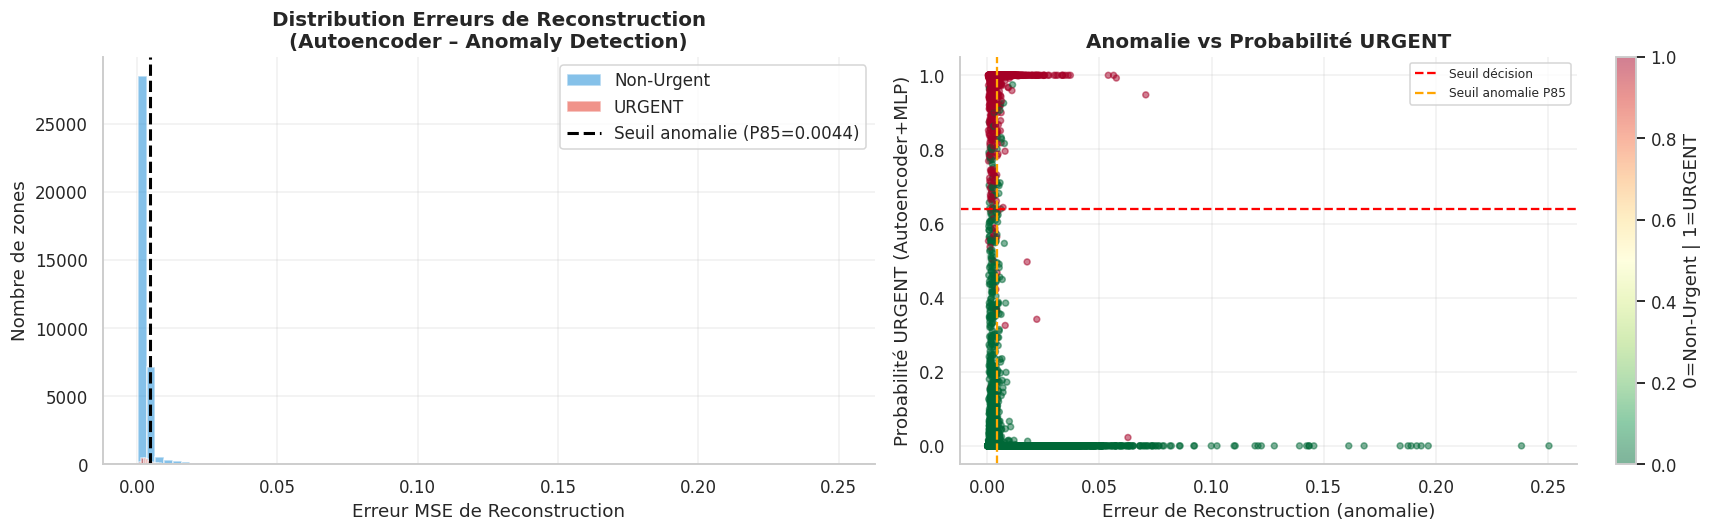

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Évaluation
ae.eval()
X_all_t = torch.tensor(X_val_sc, dtype=torch.float32).to(DEVICE)
recon_errors = ae.reconstruction_error(X_all_t).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution des erreurs de reconstruction
axes[0].hist(recon_errors[y_val == 0], bins=80, alpha=0.6,
             color="#3498db", label="Non-Urgent", edgecolor="white")
axes[0].hist(recon_errors[y_val == 1], bins=80, alpha=0.6,
             color="#e74c3c", label="URGENT", edgecolor="white")

# Seuil anomalie
thresh_ae = np.percentile(recon_errors, 85)
axes[0].axvline(thresh_ae, color="black", lw=2, linestyle="--",
                label=f"Seuil anomalie (P85={thresh_ae:.4f})")

# Titres et labels
axes[0].set_title("Distribution Erreurs de Reconstruction\n(Autoencoder – Anomaly Detection)",
                  fontweight="bold")
axes[0].set_xlabel("Erreur MSE de Reconstruction")
axes[0].set_ylabel("Nombre de zones")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Scatter : probabilité URGENT vs erreur reconstruction
sc = axes[1].scatter(
    recon_errors, ae_mlp_proba,
    c=np.array(y_val), cmap="RdYlGn_r", alpha=0.5, s=15
)

axes[1].axhline(trained_dl["Autoencoder + MLP"]["thresh"], color="red",
                linestyle="--", lw=1.5, label="Seuil décision")
axes[1].axvline(thresh_ae, color="orange", linestyle="--", lw=1.5,
                label="Seuil anomalie P85")

axes[1].set_xlabel("Erreur de Reconstruction (anomalie)")
axes[1].set_ylabel("Probabilité URGENT (Autoencoder+MLP)")
axes[1].set_title("Anomalie vs Probabilité URGENT", fontweight="bold")
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

# Barre de couleur pour y_val
plt.colorbar(sc, ax=axes[1], label="0=Non-Urgent | 1=URGENT")

plt.tight_layout()
plt.show()

---
## 9-DL. 🏆 Ranking Final des Zones – CAPEX Scoring Deep Learning (ODS3/BO3)

> Le meilleur modèle DL est appliqué sur l'ensemble du dataset pour produire le **classement définitif des zones d'investissement**.


In [ ]:
# Predictions sur tout le dataset avec le meilleur modèle DL
X_all_np = train_fe[feature_cols].fillna(0).values.astype(np.float32)
X_all_sc = scaler.transform(X_all_np).astype(np.float32)

best_dl_name = results_df_dl.iloc[0]["Modele"]

if best_dl_name == "TabNet":
    proba_all = tabnet.predict_proba(X_all_sc)[:, 1]
elif best_dl_name == "Autoencoder + MLP":
    recon_all = get_recon_error(X_all_sc).reshape(-1, 1)
    X_all_ae  = np.hstack([X_all_sc, recon_all]).astype(np.float32)
    ae_mlp_model.eval()
    with torch.no_grad():
        proba_all = ae_mlp_model(torch.tensor(X_all_ae).to(DEVICE)).cpu().numpy()
else:  # MLP
    mlp_model.eval()
    with torch.no_grad():
        proba_all = mlp_model(torch.tensor(X_all_sc).to(DEVICE)).cpu().numpy()

train_fe["proba_urgent_dl"] = proba_all
train_fe["pred_urgent_dl"]  = (proba_all >= best_dl_res["thresh"]).astype(int)

# Agrégation par ville
zone_final_dl = train_fe.groupby(CITY_COL).agg(
    n_obs             =(CITY_COL,            "count"),
    avg_capex         =("capex_score",        "mean"),
    pct_urgent_reel   =("priority",           lambda x: (x == URGENT_CLASS).mean() * 100),
    pct_urgent_predit =("pred_urgent_dl",     "mean"),
    avg_proba_urgent  =("proba_urgent_dl",    "mean"),
    avg_latency       =("latency_ms",         "mean"),
    avg_throughput    =("throughput_mbps",    "mean"),
    avg_signal        =("signal_strength_dbm","mean"),
).reset_index()

def norm_col(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-8)

# Investment Score composite : CAPEX + réel urgent + proba DL
zone_final_dl["investment_score"] = (
    norm_col(zone_final_dl["avg_capex"])        * 0.35 +
    norm_col(zone_final_dl["pct_urgent_reel"])  * 0.30 +
    norm_col(zone_final_dl["avg_proba_urgent"]) * 0.35
) * 100

zone_final_dl = zone_final_dl.sort_values("investment_score", ascending=False).reset_index(drop=True)
zone_final_dl["Rang"] = range(1, len(zone_final_dl) + 1)
zone_final_dl["Action BO3"] = zone_final_dl["investment_score"].apply(
    lambda s: "INVESTISSEMENT URGENT" if s >= 66
    else ("PLANIFIER N+1" if s >= 33 else "MONITORING")
)

display(zone_final_dl[[
    "Rang", CITY_COL, "investment_score", "avg_capex",
    "pct_urgent_reel", "avg_proba_urgent",
    "avg_latency", "avg_throughput", "Action BO3"
]].style
    .background_gradient(cmap="RdYlGn_r", subset=["investment_score"])
    .background_gradient(cmap="Reds",     subset=["pct_urgent_reel", "avg_proba_urgent"])
    .background_gradient(cmap="Reds",     subset=["avg_latency"])
    .background_gradient(cmap="Greens",   subset=["avg_throughput"])
    .format({
        "investment_score":  "{:.1f}",
        "avg_capex":         "{:.1f}",
        "pct_urgent_reel":   "{:.1f}%",
        "avg_proba_urgent":  "{:.3f}",
        "avg_latency":       "{:.1f} ms",
        "avg_throughput":    "{:.1f} Mbps",
    })
    .set_caption(f"CAPEX Investment Priority – Zone Ranking Deep Learning ({best_dl_name}) | ODS3/BO3")
)


,Rang,city,investment_score,avg_capex,pct_urgent_reel,avg_proba_urgent,avg_latency,avg_throughput,Action BO3
0,1,Benin City,87.3,51.6,6.5%,0.070,65.4 ms,65.0 Mbps,INVESTISSEMENT URGENT
1,2,Abuja,66.8,51.5,6.4%,0.069,65.9 ms,65.1 Mbps,INVESTISSEMENT URGENT
2,3,Onitsha,66.4,51.5,6.3%,0.067,64.0 ms,62.9 Mbps,INVESTISSEMENT URGENT
3,4,Lagos,58.7,51.6,6.0%,0.068,64.2 ms,64.9 Mbps,PLANIFIER N+1
4,5,Jos,56.9,51.6,6.1%,0.065,64.2 ms,64.7 Mbps,PLANIFIER N+1
5,6,Ibadan,56.0,51.6,6.0%,0.064,64.7 ms,63.4 Mbps,PLANIFIER N+1
6,7,Calabar,42.9,51.5,6.1%,0.065,64.0 ms,63.5 Mbps,PLANIFIER N+1
7,8,Aba,36.8,51.5,6.0%,0.064,65.5 ms,65.0 Mbps,PLANIFIER N+1
8,9,Ilorin,34.3,51.6,5.9%,0.062,63.1 ms,64.0 Mbps,PLANIFIER N+1
9,10,Kano,29.3,51.5,6.1%,0.065,64.0 ms,65.2 Mbps,MONITORING


## 10-DL. Dashboard Final – ODS3/BO3 Deep Learning

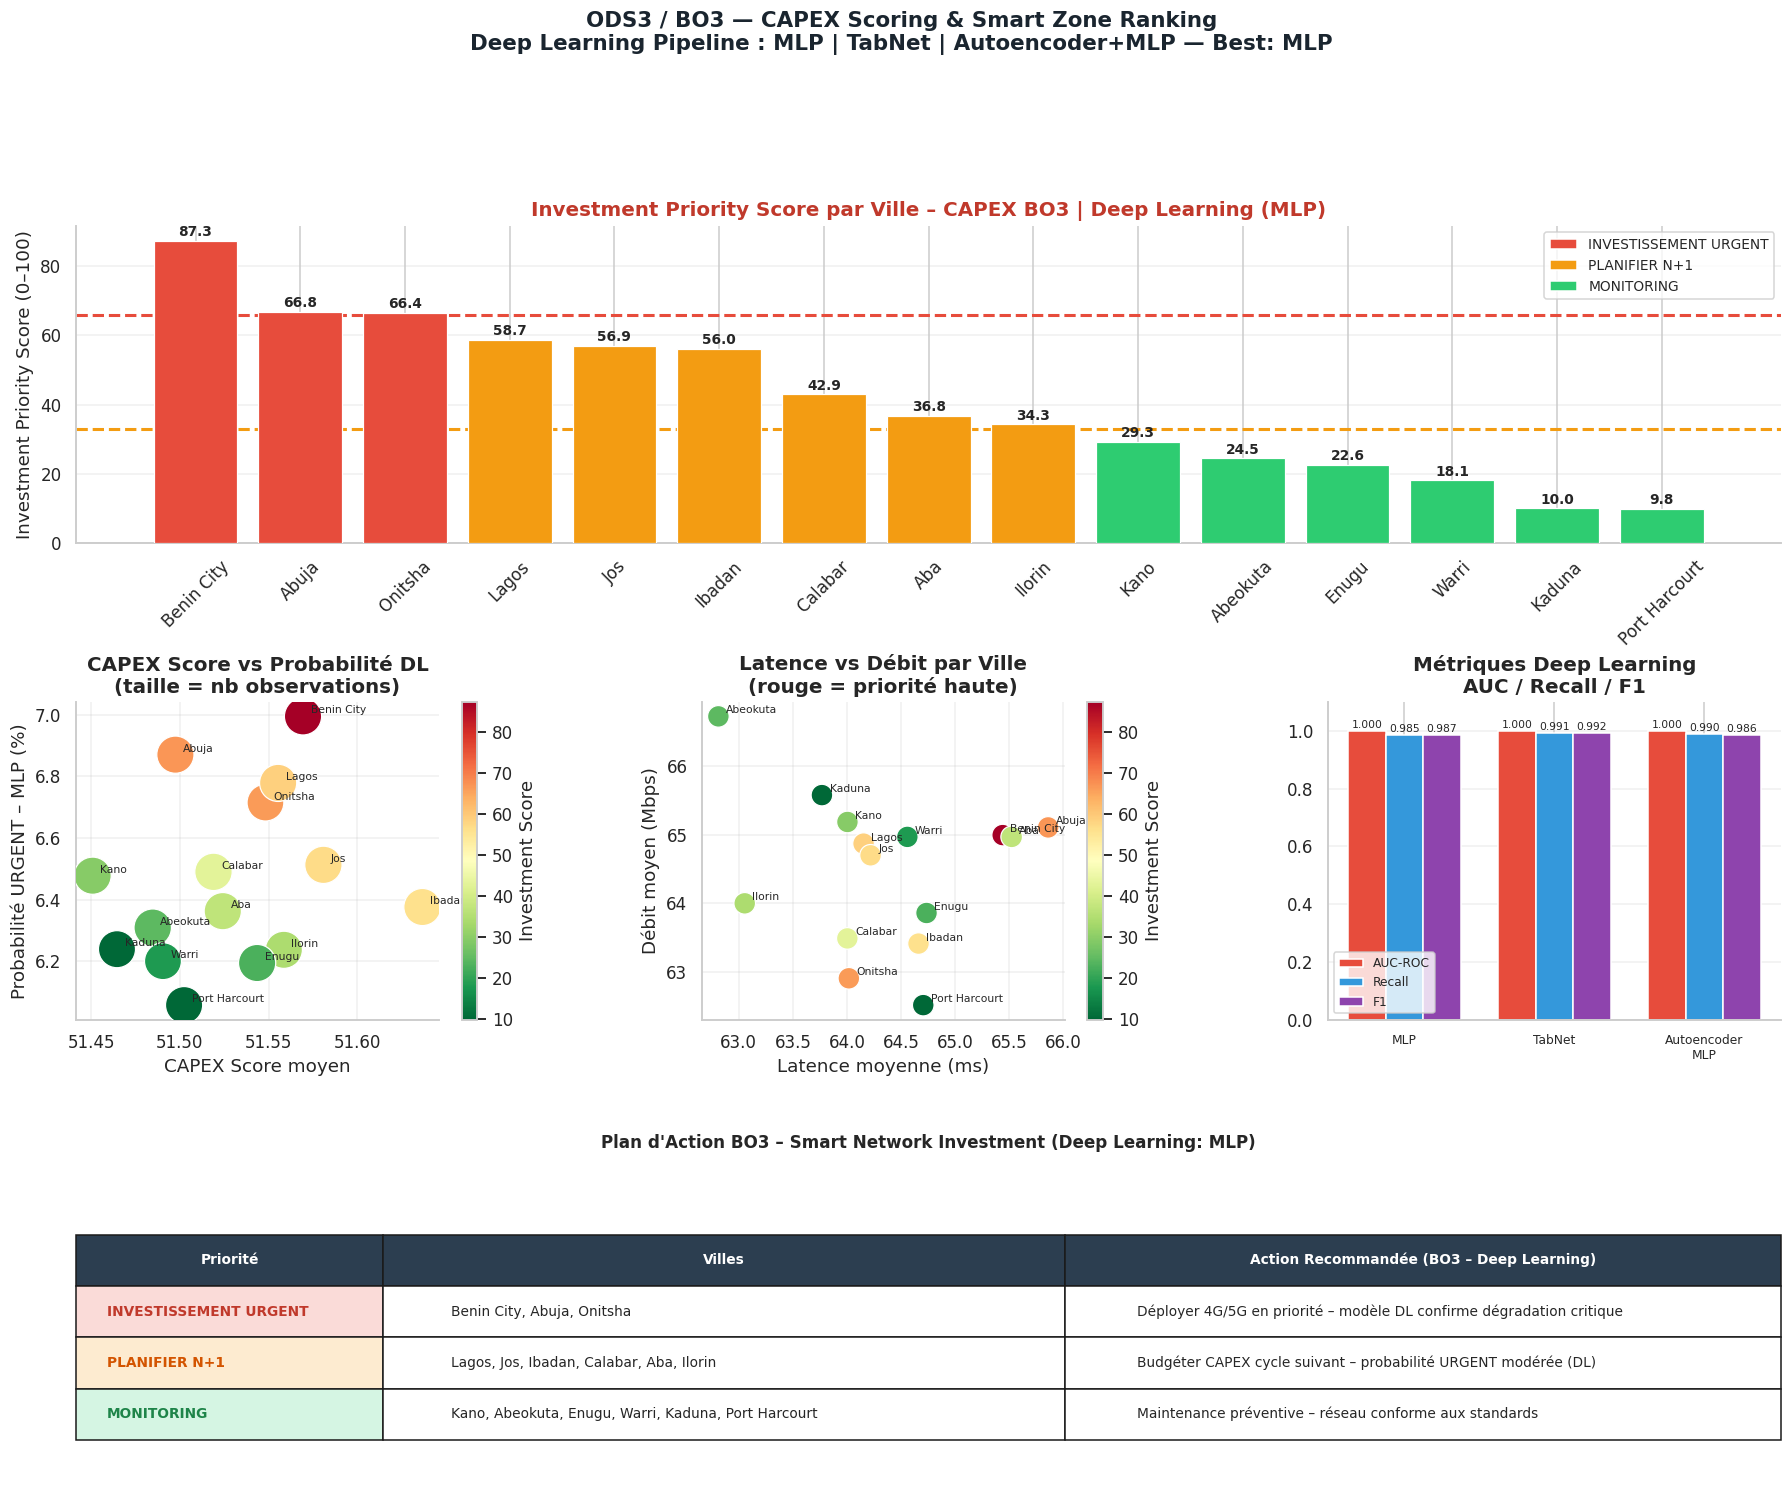

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

fig = plt.figure(figsize=(20, 15))
gs  = fig.add_gridspec(3, 3, hspace=0.50, wspace=0.38)

# ── 1. Ranking global ──────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
bar_colors = zone_final_dl["Action BO3"].map({
    "INVESTISSEMENT URGENT": "#e74c3c",
    "PLANIFIER N+1":         "#f39c12",
    "MONITORING":            "#2ecc71",
})
bars = ax1.bar(zone_final_dl[CITY_COL], zone_final_dl["investment_score"],
               color=bar_colors, edgecolor="white", linewidth=0.8, zorder=3)
for bar, score in zip(bars, zone_final_dl["investment_score"]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f"{score:.1f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
ax1.axhline(66, color="#e74c3c", linestyle="--", lw=2, label="Seuil URGENT (66)")
ax1.axhline(33, color="#f39c12", linestyle="--", lw=2, label="Seuil PLANIFIER (33)")
ax1.set_title(f"Investment Priority Score par Ville – CAPEX BO3 | Deep Learning ({best_dl_name})",
              fontsize=13, fontweight="bold", color="#c0392b")
ax1.set_ylabel("Investment Priority Score (0–100)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(True, alpha=0.3, axis="y", zorder=0)

# Légende manuelle
ax1.legend(handles=[
    Patch(facecolor="#e74c3c", label="INVESTISSEMENT URGENT"),
    Patch(facecolor="#f39c12", label="PLANIFIER N+1"),
    Patch(facecolor="#2ecc71", label="MONITORING"),
], fontsize=9, loc="upper right")

# ── 2. Scatter CAPEX vs Proba DL ──────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
sc2 = ax2.scatter(
    zone_final_dl["avg_capex"], zone_final_dl["avg_proba_urgent"] * 100,
    c=zone_final_dl["investment_score"], cmap="RdYlGn_r",
    s=zone_final_dl["n_obs"] / zone_final_dl["n_obs"].max() * 500 + 100,
    edgecolors="white", linewidth=0.8, zorder=3
)
plt.colorbar(sc2, ax=ax2, label="Investment Score")
for _, row in zone_final_dl.iterrows():
    ax2.annotate(row[CITY_COL],
                 (row["avg_capex"], row["avg_proba_urgent"] * 100),
                 textcoords="offset points", xytext=(5, 2), fontsize=7)
ax2.set_xlabel("CAPEX Score moyen")
ax2.set_ylabel(f"Probabilité URGENT – {best_dl_name} (%)")
ax2.set_title("CAPEX Score vs Probabilité DL\n(taille = nb observations)")
ax2.grid(True, alpha=0.3)

# ── 3. Latence vs Débit par ville ─────────────────────────
ax3 = fig.add_subplot(gs[1, 1])
sc3 = ax3.scatter(
    zone_final_dl["avg_latency"], zone_final_dl["avg_throughput"],
    c=zone_final_dl["investment_score"], cmap="RdYlGn_r",
    s=200, edgecolors="white", linewidth=0.8, zorder=3
)
plt.colorbar(sc3, ax=ax3, label="Investment Score")
for _, row in zone_final_dl.iterrows():
    ax3.annotate(row[CITY_COL],
                 (row["avg_latency"], row["avg_throughput"]),
                 textcoords="offset points", xytext=(5, 2), fontsize=7)
ax3.set_xlabel("Latence moyenne (ms)")
ax3.set_ylabel("Débit moyen (Mbps)")
ax3.set_title("Latence vs Débit par Ville\n(rouge = priorité haute)")
ax3.grid(True, alpha=0.3)

# ── 4. Comparaison AUC des 3 modèles DL ──────────────────
ax4 = fig.add_subplot(gs[1, 2])
names_dl  = results_df_dl["Modele"].tolist()
aucs_dl   = results_df_dl["AUC-ROC"].tolist()
recalls_dl= results_df_dl["Recall"].tolist()
f1s_dl    = results_df_dl["F1"].tolist()
x_pos     = np.arange(len(names_dl))
width = 0.25
ax4.bar(x_pos - width, aucs_dl, width, label="AUC-ROC", color="#e74c3c", edgecolor="white")
ax4.bar(x_pos,         recalls_dl, width, label="Recall", color="#3498db", edgecolor="white")
ax4.bar(x_pos + width, f1s_dl,    width, label="F1",     color="#8e44ad", edgecolor="white")
ax4.set_xticks(x_pos)
ax4.set_xticklabels([n.replace(" + ", "\n") for n in names_dl], fontsize=8)
ax4.set_ylim(0, 1.1)
ax4.set_title("Métriques Deep Learning\nAUC / Recall / F1", fontweight="bold")
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.3, axis="y")
for i, (a, r, f) in enumerate(zip(aucs_dl, recalls_dl, f1s_dl)):
    ax4.text(i - width, a + 0.01, f"{a:.3f}", ha="center", fontsize=7)
    ax4.text(i,          r + 0.01, f"{r:.3f}", ha="center", fontsize=7)
    ax4.text(i + width,  f + 0.01, f"{f:.3f}", ha="center", fontsize=7)

# ── 5. Plan d'action BO3 ──────────────────────────────────
ax5 = fig.add_subplot(gs[2, :])
ax5.axis("off")
urgent_cities = zone_final_dl[zone_final_dl["Action BO3"] == "INVESTISSEMENT URGENT"][CITY_COL].tolist()
plan_cities   = zone_final_dl[zone_final_dl["Action BO3"] == "PLANIFIER N+1"][CITY_COL].tolist()
mon_cities    = zone_final_dl[zone_final_dl["Action BO3"] == "MONITORING"][CITY_COL].tolist()
table_data = [
    ["INVESTISSEMENT URGENT", ", ".join(urgent_cities),
     "Déployer 4G/5G en priorité – modèle DL confirme dégradation critique"],
    ["PLANIFIER N+1",         ", ".join(plan_cities),
     "Budgéter CAPEX cycle suivant – probabilité URGENT modérée (DL)"],
    ["MONITORING",            ", ".join(mon_cities),
     "Maintenance préventive – réseau conforme aux standards"],
]
tbl = ax5.table(
    cellText=table_data,
    colLabels=["Priorité", "Villes", "Action Recommandée (BO3 – Deep Learning)"],
    cellLoc="left", loc="center",
    colWidths=[0.18, 0.40, 0.42]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 2.8)
for j in range(3):
    tbl[(0, j)].set_facecolor("#2c3e50")
    tbl[(0, j)].set_text_props(color="white", fontweight="bold")
tbl[(1, 0)].set_facecolor("#fadbd8"); tbl[(1, 0)].set_text_props(color="#c0392b", fontweight="bold")
tbl[(2, 0)].set_facecolor("#fdebd0"); tbl[(2, 0)].set_text_props(color="#d35400", fontweight="bold")
tbl[(3, 0)].set_facecolor("#d5f5e3"); tbl[(3, 0)].set_text_props(color="#1e8449", fontweight="bold")
ax5.set_title(f"Plan d'Action BO3 – Smart Network Investment (Deep Learning: {best_dl_name})",
              fontsize=11, fontweight="bold", pad=20)

plt.suptitle(
    f"ODS3 / BO3 — CAPEX Scoring & Smart Zone Ranking\n"
    f"Deep Learning Pipeline : MLP | TabNet | Autoencoder+MLP — Best: {best_dl_name}",
    fontsize=14, fontweight="bold", color="#1a252f", y=1.01)
plt.show()

---
## ✅ Checklist BO3 Deep Learning – Complète

- [x] Exploration & EDA qualité données
- [x] Construction du Score CAPEX composite
- [x] Feature Engineering réseau (14 variables)
- [x] SMOTE + normalisation pour DL
- [x] **MLP (MultiLayer Perceptron)** – BatchNorm + GELU + Weighted BCE
- [x] **TabNet** – attention séquentielle, feature importance native
- [x] **Autoencoder** – détection anomalies zones dégradées
- [x] **Autoencoder + MLP** – combinaison anomalie + classification
- [x] Courbes ROC & Matrices de Confusion DL
- [x] Feature Importance TabNet (attention masks)
- [x] Visualisation erreurs reconstruction Autoencoder
- [x] **Ranking final des zones + Plan d'action BO3**
- [x] **Dashboard ODS3/BO3 complet – Deep Learning**

### 🏗️ Pipeline Deep Learning Production

